In [1]:
#!pip install tqdm
#!pip install ipywidgets
#!pip install orjson isal 
#!pip install polars
#!pip install pyarrow

#!pip install matplotlib
#!pip install seaborn
#!pip install opinionated

In [1]:
import duckdb, pandas as pd, time, threading, os, glob
from tqdm.auto import tqdm

from pathlib import Path
import os
import shutil
import matplotlib.pyplot as plt
import seaborn as sns

#import opinionated
plt.style.use("opinionated_rc")
import colormaps as cmaps 



In [2]:
#!rm -rf value_of_philosophy_datasets/author_works_full.parquet

In [3]:
SNAPSHOT_PATH = "openalex-snapshot_3_11_2025/"

DB_PATH   = f"{SNAPSHOT_PATH}openalex.duckdb"  # your .duckdb file (it will be created if missing)
WORKS_GLOB = f"{SNAPSHOT_PATH}data/works/*/*.gz"  # adjust to your path





# Project_dir 

PROJECT_DIR = "value_of_philosophy_datasets/"



In [4]:
!nproc
!free -h
# check system resources

15
               total        used        free      shared  buff/cache   available
Mem:           177Gi       730Mi       176Gi       1.0Mi       454Mi       175Gi
Swap:             0B          0B          0B


# 1. Load Journal-Data

In [5]:
OUT_DIR   = f"{PROJECT_DIR}philosophy_data_issn_slices_ndjson"

In [6]:
journals_df = pd.read_csv(f"{PROJECT_DIR}philpapers_journals_with_issn.csv")

In [7]:
journals_df

,Title,ISSN,Details,Number_of_Articles,First_Year,Last_Year
0,'Ilu. Revista de Ciencias de Las Religiones,1135-4712,ISSN 11354712 738 articles between 1995 and ...,738,1995.0,2024.0
1,A Parte Rei,2172-9069,ISSN 21729069 1341 articles between 1997 and...,1341,1997.0,2011.0
2,Abstracta,1807-9792,ISSN 1807-9792 149 articles between 2004 and...,149,2004.0,2022.0
3,Accademia,1296-7645,ISSN 12967645 67 articles between 1999 and 2008,67,1999.0,2008.0
4,Acm Sigcas Computers and Society,0095-2737,ISSN 00952737 326 articles between 1976 and ...,326,1976.0,2017.0
...,...,...,...,...,...,...
1429,Годишен зборник на Филозофскиот факултет/The A...,0350-1892,ISSN 0350-1892 398 articles between 2015 and...,398,2015.0,2024.0
1430,Наукові Записки Наукма. Філософія Та Релігієзн...,2617-1678,ISSN 26171678 128 articles between 2018 and ...,128,2018.0,2025.0
1431,Схід,1728-9343,ISSN 17289343 1028 articles between 2007 and...,1028,2007.0,2018.0
1432,پژوهشنامه فلسفه دین,2228-6578,ISSN 22286578 246 articles between 2004 and ...,246,2004.0,2024.0


In [ ]:




os.makedirs(OUT_DIR, exist_ok=True)






# Your ISSN list (with hyphens, e.g. "0028-0836")
issns = list(journals_df["ISSN"])

con = duckdb.connect(DB_PATH)
con.execute("SET threads=15; SET memory_limit='164GB';")
con.execute("SET progress_bar_time=0;")  # show immediately
con.register("issn_list", pd.DataFrame({"issn": issns}))


# 2) define the long-running step
def build_matched():
    con.execute("""
        CREATE OR REPLACE TEMP TABLE matched AS
        SELECT w.*, i.issn AS issn_match
        FROM read_ndjson(?, hive_partitioning := true) AS w
        JOIN issn_list AS i
          ON COALESCE(list_contains(w.primary_location.source.issn, i.issn), false)
          OR COALESCE(w.primary_location.source.issn_l = i.issn, false);
    """, [WORKS_GLOB])

# 3) run it in a worker thread and poll progress from the main thread
worker = threading.Thread(target=build_matched, daemon=True)
worker.start()

pbar = tqdm(total=100, desc="Building matched")
while worker.is_alive():
    prog = con.query_progress()  # returns a float progress of the pending op
    if prog is not None and prog >= 0:
        pct = int(prog*100) if prog <= 1.0 else int(prog)  # handle 0..1 or 0..100
        if pct > pbar.n:
            pbar.n = min(pct, 100)
            pbar.refresh()
    time.sleep(0.5)

worker.join()
pbar.n = 100; pbar.refresh(); pbar.close()



In [28]:

con.execute("PRAGMA disable_print_progress_bar")  # show progress during long queries

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

# sanity: see what issn_match actually looks like
print(con.execute("""
  SELECT issn_match, COUNT(*) n
  FROM matched
  GROUP BY 1
  ORDER BY n DESC
  LIMIT 10
""").fetchdf())


outdir = Path(OUT_DIR).resolve()
outdir.mkdir(parents=True, exist_ok=True)

for s in tqdm(issns):
    # normalize once
    norm = s.upper().replace('-', '')

    n = con.execute("""
        SELECT COUNT(*)
        FROM matched
        WHERE upper(replace(issn_match,'-','')) = ?
    """, [norm]).fetchone()[0]

    if n == 0:
        #print(f"{s}: 0 rows — skipping")
        continue

    target = (outdir / f"{s}.ndjson").as_posix()  # literal path

    con.execute(f"""
      COPY (
        SELECT *
        FROM matched
        WHERE upper(replace(issn_match,'-','')) = '{norm}'
      )
      TO '{target}'
      (FORMAT json, ARRAY false)
    """)

 #   print("   exists:", os.path.exists(target), 
 #         "size:", os.path.getsize(target) if os.path.exists(target) else 0)

  issn_match      n
0  0009-840X  35430
1  0038-7134  28309
2  0035-0818  19236
3  0022-4812  18570
4  0026-4423  16747
5  0035-3841  14180
6  0035-2403  14046
7  0075-4269  13233
8  0022-362X  12814
9  0014-1704  11480


  0%|          | 0/1434 [00:00<?, ?it/s]

# Get author-data for authors in philosophy.

In [6]:
outdir   = f"{PROJECT_DIR}philosophy_data_issn_slices_ndjson"
outdir = Path(outdir).resolve()
print("Resolved OUT_DIR:", outdir)
files = sorted(glob.glob(str(outdir / "*.ndjson")))
print("Found", len(files), "NDJSON files")
print("First few:", files[:5])

con = duckdb.connect("data/openalex.duckdb")
con.execute("LOAD json")
con.execute("PRAGMA enable_print_progress_bar; SET progress_bar_time=0;")

# Smoke test: can DuckDB read a couple of files?
con.execute("SELECT COUNT(*) FROM read_ndjson(?)", [str(outdir / "*.ndjson")]).fetchone()

Resolved OUT_DIR: /data/oa-testing_storage/value_of_philosophy_datasets/philosophy_data_issn_slices_ndjson
Found 1213 NDJSON files
First few: ['/data/oa-testing_storage/value_of_philosophy_datasets/philosophy_data_issn_slices_ndjson/0001-2343.ndjson', '/data/oa-testing_storage/value_of_philosophy_datasets/philosophy_data_issn_slices_ndjson/0001-494X.ndjson', '/data/oa-testing_storage/value_of_philosophy_datasets/philosophy_data_issn_slices_ndjson/0001-5342.ndjson', '/data/oa-testing_storage/value_of_philosophy_datasets/philosophy_data_issn_slices_ndjson/0002-5275.ndjson', '/data/oa-testing_storage/value_of_philosophy_datasets/philosophy_data_issn_slices_ndjson/0003-0481.ndjson']


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(1417248,)

In [7]:
NDJSON_GLOB = str(outdir / "*.ndjson")

authors_sql = """
WITH works_raw AS (
  SELECT * FROM read_ndjson(?, hive_partitioning := false)
),
works_dedup AS (
  SELECT *
  FROM works_raw
  QUALIFY ROW_NUMBER() OVER (PARTITION BY id ORDER BY id) = 1
),
ua AS (
  SELECT
    id   AS paper_id,
    title AS paper_title,
    publication_year AS paper_publication_year,
    a.authorship
  FROM works_dedup
  , UNNEST(authorships) AS a(authorship)   -- 👈 column alias
)
SELECT
  paper_id,
  paper_title,
  paper_publication_year,

  authorship.author.id               AS author_id,
  authorship.author.display_name     AS author_name,
  authorship.author.orcid            AS author_orcid,

  authorship.author_position         AS author_position,
  authorship.is_corresponding        AS is_corresponding,
  authorship.raw_author_name         AS raw_author_name,
  authorship.raw_affiliation_string  AS raw_affiliation_string,
  authorship.countries               AS countries,

  -- If supported in your DuckDB (1.x): keep institution arrays
  list_transform(authorship.institutions, i -> i.id)           AS institution_ids,
  list_transform(authorship.institutions, i -> i.display_name) AS institution_names,
  list_transform(authorship.institutions, i -> i.ror)          AS institution_rors,
  list_transform(authorship.institutions, i -> i.country_code) AS institution_countries
FROM ua
"""

authors_df = con.execute(authors_sql, [NDJSON_GLOB]).fetchdf()
authors_df = authors_df.drop_duplicates(subset=["paper_id"], keep="first").reset_index(drop=True)
print(len(authors_df), "rows in authors_df")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1281016 rows in authors_df


In [8]:
author_id_frame = (
    authors_df
    .groupby("author_id", as_index=True)
    .agg(author_name=("author_name", "first"),
         count=("paper_id", "count"))
    .sort_values("count", ascending=False)
)
print("unique authors:", len(author_id_frame))
author_id_frame.head(10)

unique authors: 429126


,author_name,count
author_id,,
https://openalex.org/A5110105454,Alonzo Church,889
https://openalex.org/A5041356713,Patrick Madigan,885
https://openalex.org/A5070291767,Germain Marc’hadour,842
https://openalex.org/A5012013983,Christian Grappe,818
https://openalex.org/A5108698581,Matthieu Arnold,615
https://openalex.org/A5061959611,Maurice Nédoncelle,613
https://openalex.org/A5000884418,Fernand Van Steenberghen,525
https://openalex.org/A5018240867,G. K. Chesterton,438
https://openalex.org/A5111370080,Jean Rivière,433


In [9]:
# Drop authors_df to disk:
#author_id_frame.to_csv(f"{PROJECT_DIR}basic_author_frame.csv")

In [22]:
author_id_frame = pd.read_csv(f"{PROJECT_DIR}basic_author_frame.csv")

In [23]:
try:
    con.close()
except Exception:
    pass


In [24]:
# -------------- Configuration --------------
SNAPSHOT_ROOT = "openalex-snapshot_3_11_2025"
WORKS_GLOB = os.path.join(SNAPSHOT_ROOT, "data", "works", "updated_date=*","part_*.gz")

# You already have these in your notebook
# PROJECT_DIR: path to your project root
# author_id_frame: DataFrame whose index contains OpenAlex author IDs

BASE_OUT  = os.path.join(PROJECT_DIR, "base_authors_works")
OUT_DIR   = os.path.join(BASE_OUT, "works_parts")
LOG_DIR   = os.path.join(BASE_OUT, "logs")
DONE_DIR  = os.path.join(BASE_OUT, "done_marks")  # resume support

for d in [BASE_OUT, OUT_DIR, LOG_DIR, DONE_DIR]:
    Path(d).mkdir(parents=True, exist_ok=True)

BLOCK_SIZE   = 100_000        # lines per output file
COMPRESS_OUT = False          # set True to write .ndjson.gz outputs
N_WORKERS    = min(12, os.cpu_count() or 1)  # 10 to 14 is a good range for 16 cores


In [12]:

import os, glob, sys, io, gzip, random, string, time
from pathlib import Path
from typing import Tuple, Dict, List
from concurrent.futures import ProcessPoolExecutor, as_completed

import pandas as pd
from tqdm.auto import tqdm

# Optional faster JSON
try:
    import orjson as _fastjson
    def _loads(b: bytes): return _fastjson.loads(b)
except Exception:
    import json as _fastjson
    def _loads(b: bytes): return _fastjson.loads(b.decode("utf-8"))

# Optional faster gzip reads
try:
    from isal import igzip as igzip
    _use_igzip = True
except Exception:
    igzip = None
    _use_igzip = False


# -------------- Build author lookup sets --------------
def _get_author_series(df: pd.DataFrame) -> pd.Series:
    idx = pd.Index(df.index).astype("string")
    pat = r"(?:OPENALEX\.ORG/)?A[0-9]+$"
    sample = idx[:10000].str.upper().fillna("")
    if len(sample) > 0 and sample.str.contains(pat, regex=True).mean() > 0.2:
        return idx
    for col in ["author_id","openalex_id","id","Unnamed: 0"]:
        if col in df.columns:
            s = df[col].astype("string")
            if s.str.upper().fillna("").str.contains(pat, regex=True).any():
                return s
    return df.iloc[:, 0].astype("string")

def _norm_forms(x: str) -> Tuple[str, str]:
    x = x.strip()
    if not x:
        return "",""
    if x.lower().startswith("http"):
        short = x.rstrip("/").rsplit("/", 1)[-1].upper()
        url   = "https://openalex.org/" + short
        return short, url
    x = x.upper()
    if x.startswith("A"):
        return x, "https://openalex.org/" + x
    short = "A" + x
    return short, "https://openalex.org/" + short

if not isinstance(author_id_frame, pd.DataFrame):
    raise TypeError("author_id_frame must be a pandas DataFrame")

_raw_ids = _get_author_series(author_id_frame).dropna().astype(str)
_short_set, _url_set = set(), set()
for x in _raw_ids:
    s, u = _norm_forms(x)
    if s: _short_set.add(s)
    if u: _url_set.add(u)

# -------------- Worker utilities --------------
def _done_mark_for(path: str) -> str:
    p = Path(path)
    return os.path.join(DONE_DIR, f"{p.parent.name}__{p.name}.done")

def _pick_reader():
    # Prefer igzip for faster reads if available
    if _use_igzip:
        return igzip.open
    return gzip.open

def _line_matches(obj: dict, short_set: set, url_set: set) -> bool:
    auths = obj.get("authorships")
    if not auths:
        return False
    for a in auths:
        if not isinstance(a, dict):
            continue
        au = a.get("author")
        if not isinstance(au, dict):
            continue
        a_id = au.get("id")
        if not a_id:
            continue
        if a_id in url_set:
            return True
        short = a_id.rstrip("/").rsplit("/", 1)[-1].upper()
        if short in short_set:
            return True
    return False

def _safe_write(path: str, data: List[bytes], compress: bool):
    Path(Path(path).parent).mkdir(parents=True, exist_ok=True)
    if compress:
        with gzip.open(path, "ab") as f:
            f.writelines(data)
    else:
        with open(path, "ab") as f:
            f.writelines(data)

def _worker_process_file(fpath: str,
                         out_dir: str,
                         block_size: int,
                         compress_out: bool,
                         short_list: List[str],
                         url_list: List[str]) -> Tuple[int,int,int,int]:
    """Return tuple: (seen, kept, errors, blocks_written)"""
    seen = kept = errors = blocks = 0
    if os.path.exists(_done_mark_for(fpath)):
        return 0, 0, 0, 0

    try:
        updated_date = Path(fpath).parent.name.split("=", 1)[-1]
        partstem = Path(fpath).stem  # part_000
        pid = os.getpid()
        rnd = "".join(random.choice(string.hexdigits.lower()) for _ in range(6))
        reader_open = _pick_reader()

        # Local copies for speed
        short_set = set(short_list)
        url_set = set(url_list)

        buf: List[bytes] = []
        blk_idx = 0

        with reader_open(fpath, "rb") as gz:
            for raw_line in gz:
                if not raw_line or raw_line == b"\n":
                    continue
                seen += 1
                try:
                    obj = _loads(raw_line)
                except Exception:
                    errors += 1
                    continue
                if _line_matches(obj, short_set, url_set):
                    kept += 1
                    if not raw_line.endswith(b"\n"):
                        raw_line += b"\n"
                    buf.append(raw_line)
                    if len(buf) >= block_size:
                        outname = f"works_{updated_date}_{partstem}_pid{pid}_{rnd}_blk_{blk_idx:06d}" + (".ndjson.gz" if compress_out else ".ndjson")
                        _safe_write(os.path.join(out_dir, outname), buf, compress_out)
                        buf.clear()
                        blk_idx += 1
                        blocks += 1

        if buf:
            outname = f"works_{updated_date}_{partstem}_pid{pid}_{rnd}_blk_{blk_idx:06d}" + (".ndjson.gz" if compress_out else ".ndjson")
            _safe_write(os.path.join(out_dir, outname), buf, compress_out)
            blocks += 1

        Path(_done_mark_for(fpath)).touch()
        return seen, kept, errors, blocks

    except Exception as e:
        # Log and continue
        with open(os.path.join(LOG_DIR, "worker_errors.log"), "a", encoding="utf-8") as lf:
            lf.write(f"{fpath}\t{repr(e)}\n")
        return seen, kept, errors + 1, blocks

# -------------- Driver --------------
def run_multicore():
    files = sorted(glob.glob(WORKS_GLOB))
    if not files:
        print("No input files found. Check SNAPSHOT_ROOT and WORKS_GLOB.")
        return

    print(f"Files to scan: {len(files)}")
    print(f"Workers: {N_WORKERS}  Block size: {BLOCK_SIZE}  Compress out: {COMPRESS_OUT}")
    if _use_igzip:
        print("Using isal.igzip for input decompression")
    if _fastjson.__name__ == "orjson":
        print("Using orjson for JSON parsing")

    # Filter out files already processed
    pending = [f for f in files if not os.path.exists(_done_mark_for(f))]
    skipped = len(files) - len(pending)
    if skipped:
        print(f"Skipping {skipped} files already marked done")

    total_seen = total_kept = total_errors = total_blocks = 0
    start = time.time()

    # Important: pass author sets as lists to each worker once
    short_list = list(_short_set)
    url_list = list(_url_set)

    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futs = {
            ex.submit(_worker_process_file, f, OUT_DIR, BLOCK_SIZE, COMPRESS_OUT, short_list, url_list): f
            for f in pending
        }
        for fut in tqdm(as_completed(futs), total=len(futs), desc="Processing files"):
            seen, kept, errors, blocks = fut.result()
            total_seen  += seen
            total_kept  += kept
            total_errors += errors
            total_blocks += blocks

    elapsed = time.time() - start
    print("Done")
    print(f"Lines seen: {total_seen:,}  kept: {total_kept:,}  parse or IO errors: {total_errors:,}")
    print(f"Output blocks written: {total_blocks:,}")
    print(f"Elapsed: {elapsed:,.1f} s")
    print(f"Outputs in: {OUT_DIR}")

# Run
#if __name__ == "__main__":
run_multicore()

Files to scan: 1006
Workers: 12  Block size: 100000  Compress out: False
Using isal.igzip for input decompression
Using orjson for JSON parsing
Skipping 1006 files already marked done


Processing files: 0it [00:00, ?it/s]

Done
Lines seen: 0  kept: 0  parse or IO errors: 0
Output blocks written: 0
Elapsed: 0.0 s
Outputs in: value_of_philosophy_datasets/base_authors_works/works_parts


In [25]:
import os
import glob
import gzip
import re
import pandas as pd
from typing import Any, Dict, List, Optional, Tuple
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm import tqdm

# Choose a fast JSON parser if available
try:
    import orjson as _json
    _loads = _json.loads
    JSON_NAME = "orjson"
except Exception:
    try:
        import ujson as _json
        _loads = _json.loads
        JSON_NAME = "ujson"
    except Exception:
        import json as _json
        _loads = _json.loads
        JSON_NAME = "json"

def _loads_compat(bline: bytes) -> Dict[str, Any]:
    # orjson accepts bytes, others need str
    if JSON_NAME == "orjson":
        return _loads(bline)
    return _loads(bline.decode("utf-8"))

# Input directory with NDJSON files
# Make sure OUT_DIR is defined in your session
GLOB_PAT = os.path.join(OUT_DIR, "*.ndjson")
EXTRA_PAT = os.path.join(OUT_DIR, "*.ndjson.gz")  # optional gz support

# Precompiled regex for DOI normalization
_DOI_PREFIX = re.compile(r"^https?://doi\.org/", flags=re.IGNORECASE)

def _normalize_doi(doi_url: Optional[str]) -> Optional[str]:
    if not doi_url:
        return None
    return _DOI_PREFIX.sub("", doi_url)

def _iter_lines_binary(path: str):
    # Yield each line as bytes
    if path.endswith(".gz"):
        with gzip.open(path, "rb") as f:
            for line in f:
                if line and line.strip():
                    yield line
    else:
        with open(path, "rb") as f:
            for line in f:
                if line and line.strip():
                    yield line

def _get(d: Optional[Dict[str, Any]], *path, default=None):
    cur = d
    for key in path:
        if not isinstance(cur, dict) or key not in cur:
            return default
        cur = cur[key]
    return cur

def _to_list_if_present(v) -> Optional[List[str]]:
    if v is None:
        return None
    if isinstance(v, list):
        return [str(x) for x in v if x is not None]
    return [str(v)]

def _extract_topics(obj: Dict[str, Any]) -> Tuple[Optional[str], Optional[str], Optional[str], Optional[str]]:
    # Only use primary_topic fields. If missing, return None values.
    pt = obj.get("primary_topic")
    if not isinstance(pt, dict):
        return None, None, None, None
    primary_topic = _get(pt, "display_name")
    field         = _get(pt, "field", "display_name")
    subfield      = _get(pt, "subfield", "display_name")
    domain        = _get(pt, "domain", "display_name")
    return primary_topic, field, subfield, domain

def _extract_authors(obj: Dict[str, Any]) -> Tuple[Optional[List[Optional[str]]], Optional[List[Optional[str]]], Optional[List[Optional[str]]]]:
    # If authorships is absent, set all outputs to None. If present but empty, return empty lists.
    authorships = obj.get("authorships", None)
    if not isinstance(authorships, list):
        return None, None, None
    out_names: List[Optional[str]] = []
    out_ids: List[Optional[str]] = []
    out_orcids: List[Optional[str]] = []
    for a in authorships:
        au = a.get("author") if isinstance(a, dict) else None
        if isinstance(au, dict):
            out_names.append(au.get("display_name"))
            out_ids.append(au.get("id"))
            out_orcids.append(au.get("orcid"))
        else:
            out_names.append(None)
            out_ids.append(None)
            out_orcids.append(None)
    return out_names, out_ids, out_orcids

def _choose_best_source(obj: Dict[str, Any]) -> Dict[str, Any]:
    """
    Use only primary_location.source. If missing, return None values.
    Returns a dict with keys:
      source_id, venue, publisher, source_type, issn_l, issn_list
    """
    result = {
        "source_id": None,
        "venue": None,
        "publisher": None,
        "source_type": None,
        "issn_l": None,
        "issn_list": None,
    }
    src = _get(obj, "primary_location", "source")
    if not isinstance(src, dict):
        return result
    result["source_id"] = src.get("id")
    result["venue"] = src.get("display_name")
    result["publisher"] = src.get("publisher")
    result["source_type"] = src.get("type")
    result["issn_l"] = src.get("issn_l")
    result["issn_list"] = _to_list_if_present(src.get("issn"))
    return result

def _extract_biblio(obj: Dict[str, Any]) -> Tuple[Optional[str], Optional[str], Optional[str], Optional[str]]:
    b = obj.get("biblio")
    if not isinstance(b, dict):
        return None, None, None, None
    return b.get("volume"), b.get("issue"), b.get("first_page"), b.get("last_page")

def _extract_citation_stats(obj: Dict[str, Any]) -> Tuple[Optional[int], Optional[int], Optional[List[Dict[str, Any]]]]:
    """
    Extract citation statistics:
      - cited_by_count (prefer top level, fall back to summary_stats)
      - 2 year cited_by_count from summary_stats
      - counts_by_year list, if present
    """
    cited_by_count = obj.get("cited_by_count")
    summary_stats = obj.get("summary_stats")
    cited_by_count_2yr: Optional[int] = None

    if isinstance(summary_stats, dict):
        if cited_by_count is None:
            cited_by_count = summary_stats.get("cited_by_count")
        cited_by_count_2yr = summary_stats.get("2yr_cited_by_count")

    counts_by_year = obj.get("counts_by_year")
    if not isinstance(counts_by_year, list):
        counts_by_year = None

    return cited_by_count, cited_by_count_2yr, counts_by_year

def _transform_record(obj: Dict[str, Any]) -> Dict[str, Any]:
    # Only use obj["doi"], not ids.doi
    doi_url = obj.get("doi")
    doi = _normalize_doi(doi_url)

    authors, author_ids, author_orcids = _extract_authors(obj)
    primary_topic, field, subfield, domain = _extract_topics(obj)
    vol, issue, first_page, last_page = _extract_biblio(obj)
    source_info = _choose_best_source(obj)
    cited_by_count, cited_by_count_2yr, counts_by_year = _extract_citation_stats(obj)

    # Only use title, not display_name
    title = obj.get("title")
    pub_date = obj.get("publication_date")

    # Publication type fields at the top level
    work_type = obj.get("type")
    work_type_crossref = obj.get("type_crossref")

    return {
        "id": obj.get("id"),
        "title": title,
        "year": obj.get("publication_year"),
        "publication_date": pub_date,
        "doi_url": doi_url,
        "doi": doi,

        # Publication type
        "type": work_type,
        "type_crossref": work_type_crossref,

        # Authors
        "authors": authors,
        "author_ids": author_ids,
        "author_orcids": author_orcids,

        # Venue and ISSNs
        "venue": source_info["venue"],
        "publisher": source_info["publisher"],
        "source_id": source_info["source_id"],
        "source_type": source_info["source_type"],
        "issn_l": source_info["issn_l"],
        "issn": source_info["issn_list"],

        # Citation stats
        "cited_by_count": cited_by_count,
        "cited_by_count_2yr": cited_by_count_2yr,
        "counts_by_year": counts_by_year,

        # Biblio
        "volume": vol,
        "issue": issue,
        "first_page": first_page,
        "last_page": last_page,

        # Topics
        "primary_topic": primary_topic,
        "field": field,
        "subfield": subfield,
        "domain": domain,
    }

def _parse_file(path: str) -> List[Dict[str, Any]]:
    recs: List[Dict[str, Any]] = []
    for line in _iter_lines_binary(path):
        try:
            obj = _loads_compat(line)
        except Exception:
            continue
        try:
            recs.append(_transform_record(obj))
        except Exception:
            continue
    return recs

def load_openalex_ndjson_to_pandas(
    glob_patterns: List[str],
    max_workers: Optional[int] = None,
) -> pd.DataFrame:
    files: List[str] = []
    for pat in glob_patterns:
        files.extend(glob.glob(pat))
    files = sorted(set(files))

    if not files:
        raise FileNotFoundError("No NDJSON files found for patterns: " + ", ".join(glob_patterns))

    results: List[Dict[str, Any]] = []
    max_workers = max_workers or os.cpu_count() or 4

    with ProcessPoolExecutor(max_workers=max_workers) as ex:
        futures = {ex.submit(_parse_file, p): p for p in files}
        for fut in tqdm(as_completed(futures), total=len(futures)):
            part = fut.result()
            if part:
                results.extend(part)

    df = pd.DataFrame.from_records(results)

    # Dtypes
    try:
        df = df.convert_dtypes(dtype_backend="pyarrow")
    except Exception:
        df = df.convert_dtypes()

    if "year" in df.columns:
        try:
            df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
        except Exception:
            pass

    return df

# Run it
df = load_openalex_ndjson_to_pandas([GLOB_PAT, EXTRA_PAT], max_workers=os.cpu_count() - 4)
print(f"Parsed {len(df):,} records using {JSON_NAME}")
df.head()

100%|██████████| 919/919 [17:14<00:00,  1.13s/it]  


Parsed 22,030,421 records using orjson


,id,title,year,publication_date,doi_url,doi,type,type_crossref,authors,author_ids,...,cited_by_count_2yr,counts_by_year,volume,issue,first_page,last_page,primary_topic,field,subfield,domain
0,https://openalex.org/W2074493785,Are gram-negative bacteria a contraindication ...,1992,1992-09-01,https://doi.org/10.1067/mva.1992.38625,10.1067/mva.1992.38625,article,journal-article,"[Keith D. Calligaro, Frank J. Veith, Michael L...","[https://openalex.org/A5023383086, https://ope...",...,0,"[{'year': 2023, 'cited_by_count': 1}, {'year':...",16,3,337,6,<NA>,<NA>,<NA>,<NA>
1,https://openalex.org/W1975202923,Aortobifemoral bypass: the operation of choice...,1988,1988-09-01,https://doi.org/10.1067/mva.1988.avs0080211,10.1067/mva.1988.avs0080211,article,journal-article,"[Joseph J. Piotrowski, William H. Pearce, Darr...","[https://openalex.org/A5063547110, https://ope...",...,0,"[{'year': 2020, 'cited_by_count': 1}, {'year':...",8,3,211,8,<NA>,<NA>,<NA>,<NA>
2,https://openalex.org/W2118226724,La vocación artística entre don y don de sí,2012,2012-12-01,<NA>,<NA>,article,journal-article,[Gisèle Sapiro],[https://openalex.org/A5010222007],...,0,[],<NA>,19,0,0,<NA>,<NA>,<NA>,<NA>
3,https://openalex.org/W2016627268,Percutaneous transluminal renal angioplasty ve...,1993,1993-11-01,https://doi.org/10.1067/mva.1993.45062,10.1067/mva.1993.45062,article,journal-article,"[Henrik Weibull, David Bergqvist, Sven-Erik Be...","[https://openalex.org/A5013167854, https://ope...",...,7,"[{'year': 2022, 'cited_by_count': 2}, {'year':...",18,5,841,852,<NA>,<NA>,<NA>,<NA>
4,https://openalex.org/W4383477869,"« L’espace sportif européen : circulations, or...",2019,2019-01-01,<NA>,<NA>,book-chapter,book-chapter,"[Sylvain Dufraisse, Sébastien Moreau, Nicola S...","[https://openalex.org/A5036461438, https://ope...",...,0,[],<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [26]:
df.columns

Index(['id', 'title', 'year', 'publication_date', 'doi_url', 'doi', 'type',
       'type_crossref', 'authors', 'author_ids', 'author_orcids', 'venue',
       'publisher', 'source_id', 'source_type', 'issn_l', 'issn',
       'cited_by_count', 'cited_by_count_2yr', 'counts_by_year', 'volume',
       'issue', 'first_page', 'last_page', 'primary_topic', 'field',
       'subfield', 'domain'],
      dtype='object')

## Filtering the base author-frame

In [27]:
df['type'].value_counts()

type
article                    14951891
book-chapter                2697243
dataset                     1569709
book                         850658
preprint                     831926
review                       343531
letter                       147762
other                        143905
dissertation                 114574
paratext                      96887
editorial                     77116
libguides                     53494
report                        47580
reference-entry               39146
erratum                       28823
peer-review                   26678
supplementary-materials        8825
retraction                      599
grant                            39
standard                         35
Name: count, dtype: int64[pyarrow]

In [28]:
df = df[df['year'] >= 1950]
df = df[df['type'] >= 'article']

In [29]:
import pandas as pd
import numpy as np
import re
from collections import defaultdict

# This cell expects these to exist:
#   df                -> your huge DataFrame
#   author_id_list    -> list or set of author IDs you care about
#   issn_list         -> list or nested lists of ISSNs or ISSN-Ls to match
#
# It returns author_ratio_df with columns:
#   author_id, (optional) author_name, works_total, works_in_issn, ratio_in_issn


author_id_list = list(author_id_frame['author_id'])
issn_list = list(journals_df['ISSN'])


def compute_author_issn_ratio_streaming(df, author_id_list, issn_list, keep_author_names=True):
    # ---------- normalize targets ----------
    author_id_set = set(map(str, author_id_list))
    re_clean = re.compile(r'[^0-9X]')

    def norm_issn(x):
        if x is None or x is pd.NA:
            return None
        s = str(x).strip().upper()
        if not s:
            return None
        s = re_clean.sub('', s)
        return s if len(s) == 8 else None

    def flatten(items):
        if items is None:
            return
        if isinstance(items, (list, tuple, set)):
            for it in items:
                yield from flatten(it)
        else:
            yield items

    issn_target_set = {n for raw in flatten(issn_list) for n in [norm_issn(raw)] if n}
    target_has = issn_target_set.__contains__

    # ---------- counters ----------
    total_by_author = defaultdict(int)
    in_issn_by_author = defaultdict(int)
    name_by_author = {} if keep_author_names and 'authors' in df.columns else None

    # Pull only the columns we need to reduce attribute lookups
    col_ids   = df['author_ids'] if 'author_ids' in df.columns else pd.Series([None]).repeat(len(df))
    col_issn  = df['issn']       if 'issn'       in df.columns else pd.Series([None]).repeat(len(df))
    col_issnl = df['issn_l']     if 'issn_l'     in df.columns else pd.Series([None]).repeat(len(df))
    col_names = df['authors']    if keep_author_names and 'authors' in df.columns else pd.Series([None]).repeat(len(df))

    contains_author = author_id_set.__contains__

    def row_in_target(issn_field, issn_l_field):
        # check ISSN list column
        if isinstance(issn_field, list):
            for v in issn_field:
                n = norm_issn(v)
                if n and target_has(n):
                    return 1
        # check ISSN-L
        if issn_l_field is not None and not pd.isna(issn_l_field):
            n = norm_issn(issn_l_field)
            if n and target_has(n):
                return 1
        return 0

    # ---------- streaming pass ----------
    for author_ids, issn_field, issn_l_field, authors_field in tqdm(zip(col_ids, col_issn, col_issnl, col_names)):
        if not isinstance(author_ids, list):
            continue

        # filter to authors of interest and dedupe within the same paper
        seen = set()
        hits = []
        for a in author_ids:
            sa = str(a)
            if contains_author(sa) and sa not in seen:
                seen.add(sa)
                hits.append(sa)

        if not hits:
            continue

        in_target = row_in_target(issn_field, issn_l_field)

        # optional capture of a display name if lengths align
        if name_by_author is not None and isinstance(authors_field, list) and len(authors_field) == len(author_ids):
            for a, nm in zip(author_ids, authors_field):
                if a is None:
                    continue
                sa = str(a)
                if contains_author(sa) and isinstance(nm, str) and nm and sa not in name_by_author:
                    name_by_author[sa] = nm

        for a in hits:
            total_by_author[a] += 1
            if in_target:
                in_issn_by_author[a] += 1

    # ---------- build output ----------
    if not total_by_author:
        cols = ['author_id', 'author_name', 'works_total', 'works_in_issn', 'ratio_in_issn'] if name_by_author is not None else ['author_id', 'works_total', 'works_in_issn', 'ratio_in_issn']
        return pd.DataFrame(columns=cols)

    rows = []
    if name_by_author is None:
        for a, tot in total_by_author.items():
            in_cnt = in_issn_by_author.get(a, 0)
            rows.append((a, tot, in_cnt, in_cnt / tot if tot else np.nan))
        out = pd.DataFrame(rows, columns=['author_id', 'works_total', 'works_in_issn', 'ratio_in_issn'])
    else:
        for a, tot in total_by_author.items():
            in_cnt = in_issn_by_author.get(a, 0)
            rows.append((a, name_by_author.get(a), tot, in_cnt, in_cnt / tot if tot else np.nan))
        out = pd.DataFrame(rows, columns=['author_id', 'author_name', 'works_total', 'works_in_issn', 'ratio_in_issn'])

    return out.sort_values(['ratio_in_issn', 'works_total'], ascending=[False, False]).reset_index(drop=True)

# Example run. Set keep_author_names=False if you want to save a bit of CPU.
author_ratio_df = compute_author_issn_ratio_streaming(df, author_id_list, issn_list, keep_author_names=True)

# Optional: write to disk to avoid keeping it in memory
# author_ratio_df.to_parquet("author_ratio_df.parquet", index=False)

21438534it [03:47, 94103.97it/s] 


In [30]:
author_ratio_df#[500:520]

,author_id,author_name,works_total,works_in_issn,ratio_in_issn
0,https://openalex.org/A5073538591,Editors Philosophia Reformata,319,319,1.0
1,https://openalex.org/A5017780125,Albert Delorme,155,155,1.0
2,https://openalex.org/A5086152516,Paul Decerf,148,148,1.0
3,https://openalex.org/A5002246069,Marie-André Houdart,127,127,1.0
4,https://openalex.org/A5079899653,Editors Grazer Philosophische studien,125,125,1.0
...,...,...,...,...,...
412664,https://openalex.org/A5065072224,G. L. Hamilton,1,0,0.0
412665,https://openalex.org/A5088796322,Friedrich Pollock,1,0,0.0
412666,https://openalex.org/A5113150779,Mr. Abishek C,1,0,0.0
412667,https://openalex.org/A5052921629,A. D. N.,1,0,0.0


In [31]:
author_ratio_df = author_ratio_df[author_ratio_df['works_total'] >=3]

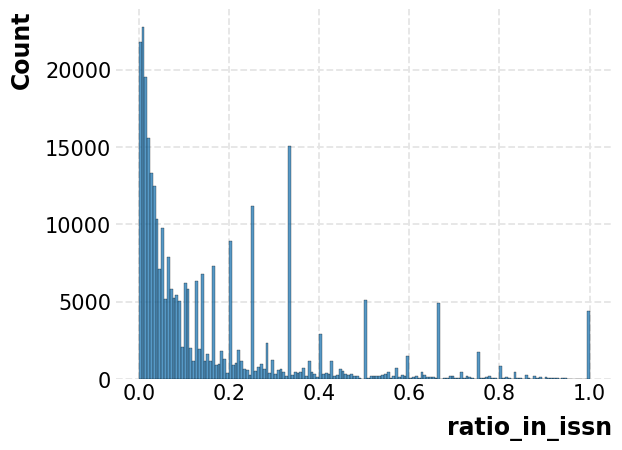

In [32]:
sns.histplot(author_ratio_df['ratio_in_issn'])
plt.savefig('ratio_histogram.png')

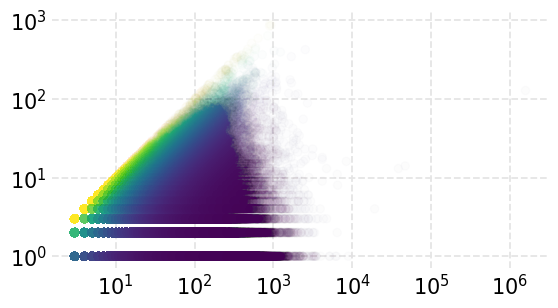

In [33]:
plt.scatter(author_ratio_df['works_total'],author_ratio_df['works_in_issn'],alpha=0.01,c=author_ratio_df['ratio_in_issn'])
plt.xscale('log')
plt.yscale('log')

plt.gca().set_aspect('equal')

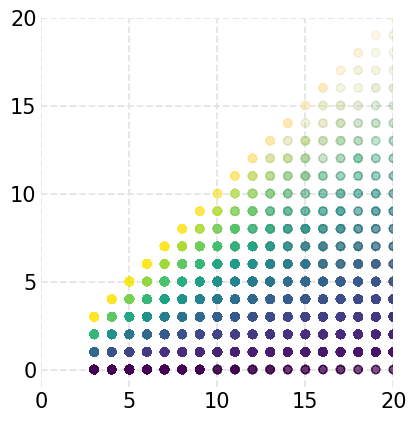

In [34]:
plt.scatter(author_ratio_df['works_total'],author_ratio_df['works_in_issn'],alpha=0.01,c=author_ratio_df['ratio_in_issn'])
plt.xlim(0,20)
plt.ylim(-1,20)
plt.gca().set_aspect('equal')

In [35]:
import pandas as pd
import numpy as np
import re

# Inputs expected to exist:
#   df                 -> original huge DataFrame (kept intact, no column dropping)
#   author_ratio_df    -> result from the previous step with author_id and ratio_in_issn
#   issn_list          -> list or nested lists of ISSNs or ISSN-Ls that define the in-list journals

# Output:
#   selected_works_df  -> all rows from df where
#                         1) at least one author is in the > 0.5 ratio group
#                         2) the work is NOT in the ISSN list
#                         3) all original columns of df are preserved

# -----------------------------
# Prepare eligible authors
# -----------------------------
if 'author_id' not in author_ratio_df.columns or 'ratio_in_issn' not in author_ratio_df.columns:
    raise ValueError("author_ratio_df must have columns 'author_id' and 'ratio_in_issn'")

eligible_authors = set(
    author_ratio_df.loc[author_ratio_df['ratio_in_issn'] > 0.5, 'author_id'].astype(str)
)

# -----------------------------
# Normalize ISSN targets
# -----------------------------
re_clean = re.compile(r'[^0-9X]')

def norm_issn(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    s = str(x).strip().upper()
    if not s:
        return None
    s = re_clean.sub('', s)
    return s if len(s) == 8 else None

def flatten(items):
    if items is None:
        return
    if isinstance(items, (list, tuple, set)):
        for it in items:
            yield from flatten(it)
    else:
        yield items

issn_target_set = {n for raw in flatten(issn_list) for n in [norm_issn(raw)] if n}
target_has = issn_target_set.__contains__

# -----------------------------
# Helpers for the scan
# -----------------------------
def row_in_target(issn_field, issn_l_field):
    # check ISSN column
    if isinstance(issn_field, list):
        for v in issn_field:
            n = norm_issn(v)
            if n and target_has(n):
                return True
    elif issn_field is not None and not (isinstance(issn_field, float) and np.isnan(issn_field)):
        n = norm_issn(issn_field)
        if n and target_has(n):
            return True

    # check ISSN-L
    if issn_l_field is not None and not (isinstance(issn_l_field, float) and np.isnan(issn_l_field)):
        n = norm_issn(issn_l_field)
        if n and target_has(n):
            return True

    return False

contains_eligible = eligible_authors.__contains__

# We do NOT drop any columns from df.
# We only read the relevant ones for building the mask.
if 'author_ids' in df.columns:
    col_ids = df['author_ids']
else:
    col_ids = pd.Series([None]).repeat(len(df))

if 'issn' in df.columns:
    col_issn = df['issn']
else:
    col_issn = pd.Series([None]).repeat(len(df))

if 'issn_l' in df.columns:
    col_l = df['issn_l']
else:
    col_l = pd.Series([None]).repeat(len(df))

# -----------------------------
# Single pass build of a boolean mask
# -----------------------------
n = len(df)
mask = np.zeros(n, dtype=bool)

for i, (author_ids, issn_field, issn_l_field) in enumerate(zip(col_ids, col_issn, col_l)):
    # Must contain at least one eligible author
    if not isinstance(author_ids, list):
        continue

    found = False
    for a in author_ids:
        if contains_eligible(str(a)):
            found = True
            break
    if not found:
        continue

    # Include only if the work is outside the ISSN list
    if not row_in_target(issn_field, issn_l_field):
        mask[i] = True

# This keeps all columns from the original df
selected_works_df = df[mask].copy()

In [37]:
selected_works_df.columns

Index(['id', 'title', 'year', 'publication_date', 'doi_url', 'doi', 'type',
       'type_crossref', 'authors', 'author_ids', 'author_orcids', 'venue',
       'publisher', 'source_id', 'source_type', 'issn_l', 'issn',
       'cited_by_count', 'cited_by_count_2yr', 'counts_by_year', 'volume',
       'issue', 'first_page', 'last_page', 'primary_topic', 'field',
       'subfield', 'domain'],
      dtype='object')

In [9]:
#selected_works_df.to_csv('value_of_philosophy_datasets/selected_issn_non_philosophy_papers.csv')
#selected_works_df = pd.read_csv('value_of_philosophy_datasets/selected_issn_non_philosophy_papers.csv')


In [38]:
# Optional: materialize to disk to keep memory headroom
# selected_works_df.to_parquet("authors_gt_0p5_outside_issn.parquet", index=False)

# Optional: quick sanity checks
#print(f"Eligible authors: {len(eligible_authors)}")
print(f"Selected works outside ISSN list: {len(selected_works_df)}")
display(selected_works_df.head())

Selected works outside ISSN list: 108059


,id,title,year,publication_date,doi_url,doi,type,type_crossref,authors,author_ids,...,cited_by_count_2yr,counts_by_year,volume,issue,first_page,last_page,primary_topic,field,subfield,domain
90,https://openalex.org/W3170871026,Mesure d'indice des guides plans Ga_1-xIn_xAs_...,1994,1994-01-01,<NA>,<NA>,article,proceedings-article,"[E. M. Skouri, Pauline Martín, P. Grech, Chris...","[https://openalex.org/A5003504516, https://ope...",...,0,[],<NA>,<NA>,<NA>,<NA>,Time-of-Flight Imaging Techniques,Physics and Astronomy,Instrumentation,Physical Sciences
364,https://openalex.org/W263482430,Medier och ledarskap,2004,2004-01-01,<NA>,<NA>,article,journal-article,"[Thomas Svensson, Johan E. Gustafsson]","[https://openalex.org/A5050285122, https://ope...",...,0,[],<NA>,<NA>,<NA>,<NA>,Research Methodology in Social Sciences and Ed...,Social Sciences,Education,Social Sciences
892,https://openalex.org/W2481415754,The argument from combined order and adaptation.,2010,2010-10-12,https://doi.org/10.1037/12271-016,10.1037/12271-016,book-chapter,book-chapter,"[James M'Cosh, George Dickie]","[https://openalex.org/A5014085935, https://ope...",...,0,[],<NA>,<NA>,420,439,<NA>,<NA>,<NA>,<NA>
1058,https://openalex.org/W2777507280,The Chinese Tiger Mother,2011,2011-12-01,<NA>,<NA>,article,journal-article,[Jacek Hołówka],[https://openalex.org/A5025713561],...,0,[],2,<NA>,359,370,<NA>,<NA>,<NA>,<NA>
1204,https://openalex.org/W3129865687,Controversy and modernity,2015,2015-01-01,<NA>,<NA>,article,journal-article,[Brendan Larvor],[https://openalex.org/A5074457128],...,0,[],<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [39]:
selected_works_df.columns

Index(['id', 'title', 'year', 'publication_date', 'doi_url', 'doi', 'type',
       'type_crossref', 'authors', 'author_ids', 'author_orcids', 'venue',
       'publisher', 'source_id', 'source_type', 'issn_l', 'issn',
       'cited_by_count', 'cited_by_count_2yr', 'counts_by_year', 'volume',
       'issue', 'first_page', 'last_page', 'primary_topic', 'field',
       'subfield', 'domain'],
      dtype='object')

In [40]:
selected_works_df = selected_works_df[selected_works_df['year'] > 1960]

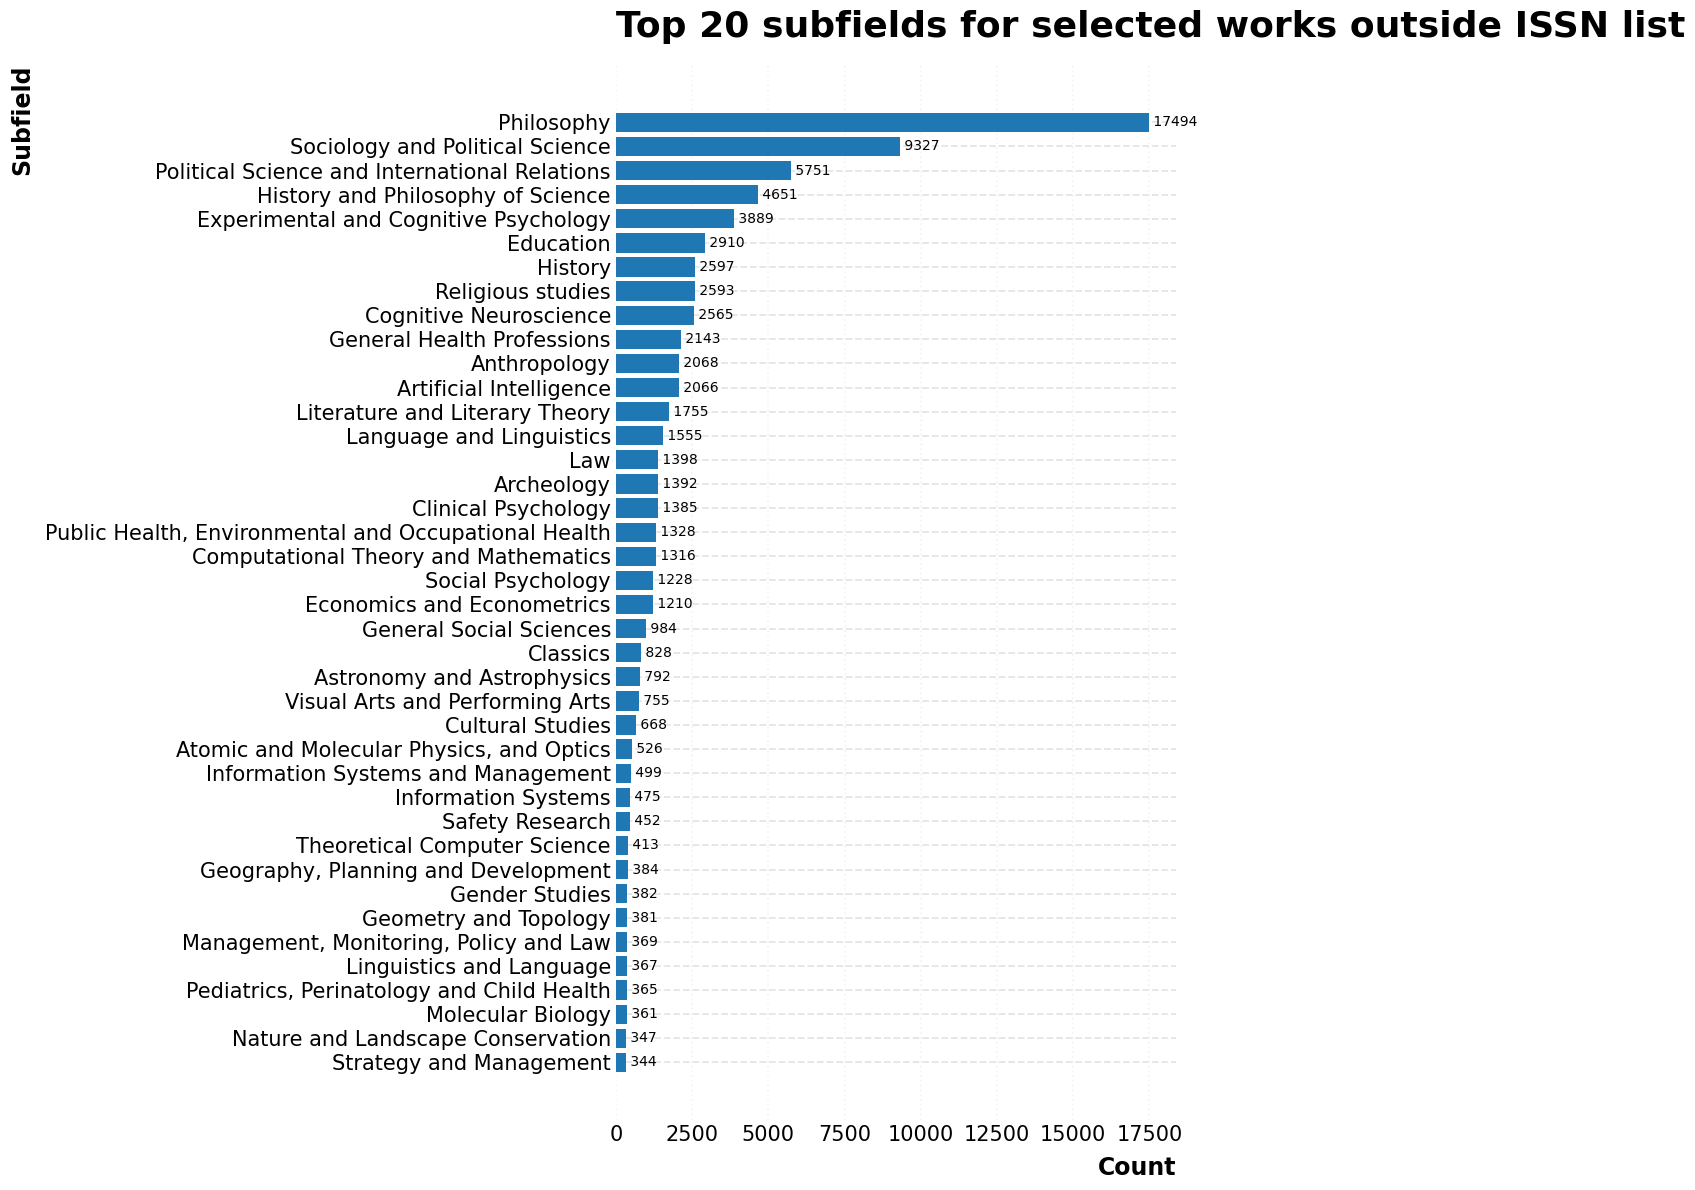

In [41]:

# Assumes selected_works_df exists and has a 'subfield' column

s = selected_works_df['subfield'].dropna()

# Optional: drop empty strings or non string entries
s = s[s.map(lambda x: isinstance(x, str) and x.strip() != '')]

top20 = s.value_counts().head(40).sort_values(ascending=True)

# Plot
fig, ax = plt.subplots(figsize=(12, 12))
ax.barh(top20.index.astype(str), top20.values)
ax.set_xlabel('Count')
ax.set_ylabel('Subfield')
ax.set_title('Top 20 subfields for selected works outside ISSN list')

# Annotate counts
for i, v in enumerate(top20.values):
    ax.text(v, i, f' {v}', va='center')

ax.grid(axis='x', linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

In [42]:
top20

subfield
Strategy and Management                                   344
Nature and Landscape Conservation                         347
Molecular Biology                                         361
Pediatrics, Perinatology and Child Health                 365
Linguistics and Language                                  367
Management, Monitoring, Policy and Law                    369
Geometry and Topology                                     381
Gender Studies                                            382
Geography, Planning and Development                       384
Theoretical Computer Science                              413
Safety Research                                           452
Information Systems                                       475
Information Systems and Management                        499
Atomic and Molecular Physics, and Optics                  526
Cultural Studies                                          668
Visual Arts and Performing Arts                           755

In [43]:
disciplines_to_remove = ['Philosophy','History and Philosophy of Science']

selected_works_philo_dropped_df = selected_works_df[~selected_works_df['subfield'].isin(disciplines_to_remove)]

selected_works_philo_dropped_df = selected_works_philo_dropped_df[selected_works_philo_dropped_df['type'] == 'article']

#selected_works_philo_dropped_df = selected_works_philo_dropped_df.drop_duplicates(by='id

In [44]:
selected_works_philo_dropped_df

,id,title,year,publication_date,doi_url,doi,type,type_crossref,authors,author_ids,...,cited_by_count_2yr,counts_by_year,volume,issue,first_page,last_page,primary_topic,field,subfield,domain
90,https://openalex.org/W3170871026,Mesure d'indice des guides plans Ga_1-xIn_xAs_...,1994,1994-01-01,<NA>,<NA>,article,proceedings-article,"[E. M. Skouri, Pauline Martín, P. Grech, Chris...","[https://openalex.org/A5003504516, https://ope...",...,0,[],<NA>,<NA>,<NA>,<NA>,Time-of-Flight Imaging Techniques,Physics and Astronomy,Instrumentation,Physical Sciences
364,https://openalex.org/W263482430,Medier och ledarskap,2004,2004-01-01,<NA>,<NA>,article,journal-article,"[Thomas Svensson, Johan E. Gustafsson]","[https://openalex.org/A5050285122, https://ope...",...,0,[],<NA>,<NA>,<NA>,<NA>,Research Methodology in Social Sciences and Ed...,Social Sciences,Education,Social Sciences
1058,https://openalex.org/W2777507280,The Chinese Tiger Mother,2011,2011-12-01,<NA>,<NA>,article,journal-article,[Jacek Hołówka],[https://openalex.org/A5025713561],...,0,[],2,<NA>,359,370,<NA>,<NA>,<NA>,<NA>
1204,https://openalex.org/W3129865687,Controversy and modernity,2015,2015-01-01,<NA>,<NA>,article,journal-article,[Brendan Larvor],[https://openalex.org/A5074457128],...,0,[],<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1299,https://openalex.org/W363208569,ELEMENTARNE ODREDNICE SVIJESTI KOD FENOMENOLOG...,2011,2011-05-02,<NA>,<NA>,article,journal-article,[Petar Bodlović],[https://openalex.org/A5014973696],...,0,[],<NA>,<NA>,53,66,<NA>,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22017357,https://openalex.org/W2556758327,Precaution and governance of emerging technolo...,2016,2016-11-11,https://doi.org/10.1126/science.aah5125,10.1126/science.aah5125,article,journal-article,"[Gregory E. Kaebnick, Elizabeth Heitman, James...","[https://openalex.org/A5084947003, https://ope...",...,12,"[{'year': 2025, 'cited_by_count': 3}, {'year':...",354,6313,710,711,Risk Perception and Management,Social Sciences,Sociology and Political Science,Social Sciences
22022883,https://openalex.org/W2979642192,Safety and efficacy of non-steroidal anti-infl...,2019,2019-10-09,https://doi.org/10.1002/bjs.11326,10.1002/bjs.11326,article,journal-article,"[Stephen J. Chapman, Daniel Clerc, Ruth Blanco...","[https://openalex.org/A5064503714, https://ope...",...,16,"[{'year': 2025, 'cited_by_count': 3}, {'year':...",107,2,e161,e169,Enhanced Recovery After Surgery,Medicine,Surgery,Health Sciences
22024071,https://openalex.org/W2161646593,Implementing moral case deliberation in Dutch ...,2008,2008-01-01,https://doi.org/10.24894/bf.2008.01010,10.24894/bf.2008.01010,article,journal-article,"[Guy Widdershoven, Bert Lendemeijer, Ezra van ...","[https://openalex.org/A5031202036, https://ope...",...,1,"[{'year': 2025, 'cited_by_count': 1}, {'year':...",<NA>,<NA>,<NA>,<NA>,Evaluation and Performance Assessment,Decision Sciences,Management Science and Operations Research,Social Sciences
22026425,https://openalex.org/W2020346614,A generic and flexible simulation-based analys...,2015,2015-04-27,https://doi.org/10.1080/00207543.2015.1037405,10.1080/00207543.2015.1037405,article,journal-article,"[Yannick Kergosien, Válerie Bélanger, P. Soria...","[https://openalex.org/A5014400532, https://ope...",...,6,"[{'year': 2025, 'cited_by_count': 5}, {'year':...",53,24,7299,7316,Facility Location and Emergency Management,"Business, Management and Accounting",Organizational Behavior and Human Resource Man...,Social Sciences


In [45]:
selected_works_philo_dropped_df.to_csv(f"{PROJECT_DIR}selected_works_philo_dropped_frame.csv")

In [8]:
selected_works_philo_dropped_df = pd.read_csv(f"{PROJECT_DIR}selected_works_philo_dropped_frame.csv")

# Collect the matches

In [ ]:
Rerun!!!

In [18]:
#!rm -rf value_of_philosophy_datasets/journal_year_author_matches
#

In [47]:
import os, glob, sys, io, gzip, random, string, time, ast
from pathlib import Path
from typing import Tuple, Dict, List, Any
from concurrent.futures import ProcessPoolExecutor, as_completed
from collections.abc import Iterable as ABCIterable

import pandas as pd
from tqdm.auto import tqdm

# -------------- Configuration --------------
SNAPSHOT_ROOT = "openalex-snapshot_3_11_2025"
WORKS_GLOB = os.path.join(SNAPSHOT_ROOT, "data", "works", "updated_date=*","part_*.gz")

# You already have these in your notebook:
# PROJECT_DIR: path to your project root
# selected_works_df: DataFrame of focal works you want matches for

BASE_OUT        = os.path.join(PROJECT_DIR, "journal_year_author_matches")
OUT_DATA_DIR    = os.path.join(BASE_OUT, "works_matches_ndjson")   # full JSON lines
OUT_LINKS_DIR   = os.path.join(BASE_OUT, "match_links_tsv")        # link tables
OUT_FLAT_DIR    = os.path.join(BASE_OUT, "works_flat_parquet")     # fast to read

LOG_DIR         = os.path.join(BASE_OUT, "logs")
DONE_DIR        = os.path.join(BASE_OUT, "done_marks")  # resume support

for d in [BASE_OUT, OUT_DATA_DIR, OUT_LINKS_DIR, OUT_FLAT_DIR, LOG_DIR, DONE_DIR]:
    Path(d).mkdir(parents=True, exist_ok=True)

# Flush buffers after this many matched lines
BLOCK_SIZE_LINES = 10_000

COMPRESS_OUT     = False  # True -> write .ndjson.gz

_CPU_COUNT = os.cpu_count() or 1
N_WORKERS  = max(1, _CPU_COUNT - 4)  # use n_cores - 4

# Scenario radii: plus minus 1, 2, 3 years and authors
SCENARIO_LEVELS = (1, 2, 3)
MAX_YEAR_DIFF   = max(SCENARIO_LEVELS)
MAX_AUTH_DIFF   = max(SCENARIO_LEVELS)

# Flat parquet configuration for fast loading
WRITE_FLAT_PARQUET      = True
FLAT_PARQUET_CHUNK_ROWS = 50_000  # rows per parquet chunk file

# -------------- Optional faster JSON --------------
try:
    import orjson as _fastjson_backend
    def _loads(b: bytes) -> Any:
        return _fastjson_backend.loads(b)
    def _dumps(obj: Any) -> bytes:
        return _fastjson_backend.dumps(obj)
except Exception:
    import json as _fastjson_backend
    def _loads(b: bytes) -> Any:
        return _fastjson_backend.loads(b.decode("utf-8"))
    def _dumps(obj: Any) -> bytes:
        return _fastjson_backend.dumps(obj).encode("utf-8")

# -------------- Optional faster gzip reads --------------
try:
    from isal import igzip as igzip
    _use_igzip = True
except Exception:
    igzip = None
    _use_igzip = False

def _pick_reader():
    if _use_igzip:
        return igzip.open
    return gzip.open

# -------------- Generic missing value helper --------------
def _is_missing(v: Any) -> bool:
    """
    Treat None and scalar NaNs as missing.
    Treat sequences (lists, tuples, sets, arrays) as non missing.
    Strings are missing only if empty or whitespace.
    """
    if v is None:
        return True

    if isinstance(v, str):
        return not v.strip()

    if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
        # For lists or arrays we treat "exists at all" as non missing
        return False

    try:
        return bool(pd.isna(v))
    except Exception:
        return False

# -------------- Selected works index helpers --------------
def _norm_work_id(x: str) -> str:
    """Normalize work IDs to full OpenAlex URL without trailing slash."""
    x = str(x).strip()
    if not x:
        return ""
    if x.lower().startswith("http"):
        return x.rstrip("/")
    x = x.upper()
    if x.startswith("W"):
        return "https://openalex.org/" + x
    return x.rstrip("/")

def _count_authors_from_row(row: pd.Series) -> int:
    """
    Best effort author count from a row in selected_works_df.
    Handles lists, arrays and stringified lists.
    """
    for col in ("author_ids", "authors"):
        if col not in row.index:
            continue
        v = row[col]
        if _is_missing(v):
            continue

        # List-like (list, tuple, set, numpy array etc)
        if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
            try:
                return len(v)
            except TypeError:
                pass

        # String, possibly "['id1', 'id2']" or "name1, name2"
        if isinstance(v, str):
            s = v.strip()
            if not s:
                continue

            # Try to parse as Python literal list
            if s.startswith("[") and s.endswith("]"):
                try:
                    parsed = ast.literal_eval(s)
                    if isinstance(parsed, ABCIterable) and not isinstance(parsed, (str, bytes)):
                        try:
                            return len(parsed)
                        except TypeError:
                            pass
                except Exception:
                    pass
                # Fallback: comma count
                return s.count(",") + 1

            # Otherwise treat as comma separated
            return s.count(",") + 1

        # Unknown non missing object, assume at least one author
        return 1

    return 0

def _norm_journal_from_row(row: pd.Series) -> str:
    """
    Build the journal_key for selected_works_df:
      - prefer issn_l if present
      - else issn
      - if list-like, take first element
      - if semicolon string, take part before first semicolon
    """
    v = None

    if "issn_l" in row.index and not _is_missing(row["issn_l"]):
        v = row["issn_l"]
    elif "issn" in row.index and not _is_missing(row["issn"]):
        v = row["issn"]

    if v is None:
        return ""

    if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
        v = next(iter(v), "")
    v = str(v).strip()
    if not v:
        return ""

    return v.split(";")[0].strip()

def build_selected_index(df: pd.DataFrame):
    """
    Build:
      journal_index: dict[journal_key] -> list of (selected_work_id, year, n_authors)
      selected_id_list: list of normalized selected work IDs
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("selected_works_df must be a pandas DataFrame")

    journal_index: Dict[str, List[Tuple[str, int, int]]] = {}
    selected_ids_set = set()

    missing = {"id", "year"} - set(df.columns)
    if missing:
        raise ValueError(f"selected_works_df is missing required columns: {missing}")

    for _, row in df.iterrows():
        journal_key = _norm_journal_from_row(row)
        if not journal_key:
            continue

        year_val = row["year"]
        try:
            year_int = int(year_val)
        except Exception:
            continue

        n_auth = _count_authors_from_row(row)
        work_id = _norm_work_id(row["id"])
        if not work_id:
            continue

        journal_index.setdefault(journal_key, []).append((work_id, year_int, n_auth))
        selected_ids_set.add(work_id)

    return journal_index, list(selected_ids_set)

# -------------- Raw works helpers (from OpenAlex JSON) --------------
def _extract_journal_from_work(obj: dict) -> str:
    """
    Build journal_key from a raw work:
      - host_venue.issn_l if available
      - else host_venue.issn (first element)
      - if host_venue missing, fall back to primary_location.source in same way
      - semicolon separated strings are cut at the first semicolon
    """
    venue = obj.get("host_venue")
    if not isinstance(venue, dict) or not venue:
        primary = obj.get("primary_location") or {}
        if isinstance(primary, dict):
            source = primary.get("source")
            if isinstance(source, dict):
                venue = source
    if not isinstance(venue, dict):
        return ""
    issn_l = venue.get("issn_l")
    if issn_l:
        return str(issn_l).strip()
    issn = venue.get("issn")
    if isinstance(issn, ABCIterable) and not isinstance(issn, (str, bytes)):
        issn = next(iter(issn), "")
    if isinstance(issn, str) and issn.strip():
        return issn.split(";")[0].strip()
    return ""

def _extract_year_from_work(obj: dict):
    y = obj.get("publication_year") or obj.get("year")
    if isinstance(y, int):
        return y
    if isinstance(y, str) and y.isdigit():
        return int(y)
    pub_date = obj.get("publication_date") or obj.get("from_publication_date")
    if isinstance(pub_date, str) and len(pub_date) >= 4 and pub_date[:4].isdigit():
        return int(pub_date[:4])
    return None

def _count_authors_from_work(obj: dict) -> int:
    auths = obj.get("authorships")
    if isinstance(auths, list):
        return len(auths)
    return 0

def _extract_citations_from_work(obj: dict):
    """
    Extract outgoing citations and counts:
      - referenced_works: list of work IDs this work cites
      - n_references: length of that list
      - cited_by_count: integer count of incoming citations (OpenAlex field)
    """
    refs = obj.get("referenced_works") or []
    if not isinstance(refs, list):
        refs = []
    n_refs = len(refs)

    cit_count = obj.get("cited_by_count")
    if cit_count is None:
        cit_count = 0
    else:
        try:
            cit_count = int(cit_count)
        except Exception:
            cit_count = 0

    return refs, n_refs, cit_count

# -------------- Global lookup for workers --------------
_MATCH_JOURNAL_INDEX: Dict[str, List[Tuple[str, int, int]]] = {}
_MATCH_SELECTED_IDS: set = set()

def _init_worker(journal_index, selected_ids, max_year_diff, max_auth_diff):
    """
    Called once per worker process. Stores shared lookup structures as globals.
    """
    global _MATCH_JOURNAL_INDEX, _MATCH_SELECTED_IDS, MAX_YEAR_DIFF, MAX_AUTH_DIFF
    _MATCH_JOURNAL_INDEX = journal_index
    _MATCH_SELECTED_IDS = set(selected_ids)
    MAX_YEAR_DIFF = max_year_diff
    MAX_AUTH_DIFF = max_auth_diff

def _done_mark_for(path: str) -> str:
    p = Path(path)
    return os.path.join(DONE_DIR, f"{p.parent.name}__{p.name}.done")

def _open_out_stream(path: str, compress: bool):
    if compress:
        return gzip.open(path, "wb")
    return open(path, "wb")

def _find_matches_for_work(journal_key: str, year: int, n_auth: int) -> List[Tuple[str, int, int, int]]:
    """
    Return list of matches for a work given its journal_key, year and n_auth.

    Each element is (selected_work_id, scenario_level, year_diff, author_diff).
    Scenario levels are 1, 2, 3 based on plus minus year and authors.
    """
    if not _MATCH_JOURNAL_INDEX:
        return []

    candidates = _MATCH_JOURNAL_INDEX.get(journal_key)
    if not candidates:
        return []

    matches: List[Tuple[str, int, int, int]] = []
    for sel_id, sel_year, sel_auth in candidates:
        dy = abs(year - sel_year)
        if dy > MAX_YEAR_DIFF:
            continue
        da = abs(n_auth - sel_auth)
        if da > MAX_AUTH_DIFF:
            continue
        scenario = None
        for s in SCENARIO_LEVELS:
            if dy <= s and da <= s:
                scenario = s
                break
        if scenario is None:
            continue
        matches.append((sel_id, scenario, dy, da))
    return matches

# -------------- Worker function --------------
def _worker_process_file(fpath: str,
                         out_data_dir: str,
                         out_links_dir: str,
                         block_lines: int,
                         compress_out: bool) -> Tuple[int, int, int, int]:
    """
    Process one gzipped works part file.

    Returns (seen, kept, errors, link_rows_written).
    """
    seen = kept = errors = link_rows = 0

    if os.path.exists(_done_mark_for(fpath)):
        return 0, 0, 0, 0

    try:
        updated_date = Path(fpath).parent.name.split("=", 1)[-1]
        partstem = Path(fpath).stem
        pid = os.getpid()
        rnd = "".join(random.choice(string.hexdigits.lower()) for _ in range(6))
        reader_open = _pick_reader()

        # Output file names for this input part
        data_out_name = f"matches_{updated_date}_{partstem}_pid{pid}_{rnd}" + (".ndjson.gz" if compress_out else ".ndjson")
        links_out_name = f"matches_{updated_date}_{partstem}_pid{pid}_{rnd}.tsv"

        data_out_path = os.path.join(out_data_dir, data_out_name)
        links_out_path = os.path.join(out_links_dir, links_out_name)

        data_buf: List[bytes] = []
        links_buf: List[str] = []
        data_fp = None
        links_fp = None

        # For fast Parquet flat output
        flat_buf: List[dict] = []
        flat_chunk_idx = 0
        flat_enabled = WRITE_FLAT_PARQUET

        link_header = "matched_work_id\tselected_work_id\tscenario\tyear_diff\tauthor_diff\n"

        with reader_open(fpath, "rb") as gz:
            for raw_line in gz:
                if not raw_line or raw_line == b"\n":
                    continue
                seen += 1
                try:
                    obj = _loads(raw_line)
                except Exception:
                    errors += 1
                    continue

                work_id = obj.get("id")
                if not work_id:
                    continue
                norm_id = _norm_work_id(work_id)

                # Skip if this work itself is in the selected set
                if norm_id in _MATCH_SELECTED_IDS:
                    continue

                # Extract journal, year, n_auth once
                journal_key = _extract_journal_from_work(obj)
                if not journal_key:
                    continue
                year = _extract_year_from_work(obj)
                if year is None:
                    continue
                n_auth = _count_authors_from_work(obj)

                # Find matches for these attributes
                matches = _find_matches_for_work(journal_key, year, n_auth)
                if not matches:
                    continue

                kept += 1

                # Extract citation info
                referenced_works, n_references, cited_by_count = _extract_citations_from_work(obj)

                # Link records (TSV with labeled columns)
                for sel_id, scenario, dy, da in matches:
                    links_buf.append(f"{norm_id}\t{sel_id}\t{scenario}\t{dy}\t{da}\n")
                link_rows += len(matches)

                # Annotate object with match info and dump full JSON line
                obj["_matched_to"] = [
                    {
                        "selected_id": sel_id,
                        "scenario": scenario,
                        "year_diff": dy,
                        "author_diff": da,
                    }
                    for sel_id, scenario, dy, da in matches
                ]
                out_bytes = _dumps(obj)
                if not out_bytes.endswith(b"\n"):
                    out_bytes += b"\n"
                data_buf.append(out_bytes)

                # Flat record for fast Parquet loading (including citations)
                if flat_enabled:
                    flat_buf.append(
                        {
                            "work_id": norm_id,
                            "journal_key": journal_key,
                            "year": year,
                            "n_authors": n_auth,
                            "referenced_works": referenced_works,
                            "n_references": n_references,
                            "cited_by_count": cited_by_count,
                        }
                    )

                # Flush NDJSON buffer
                if len(data_buf) >= block_lines:
                    if data_fp is None:
                        data_fp = _open_out_stream(data_out_path, compress_out)
                    data_fp.writelines(data_buf)
                    data_buf.clear()

                # Flush link buffer
                if len(links_buf) >= block_lines:
                    if links_fp is None:
                        links_fp = open(links_out_path, "w", encoding="utf-8")
                        links_fp.write(link_header)
                    links_fp.writelines(links_buf)
                    links_buf.clear()

                # Flush flat Parquet buffer
                if flat_enabled and len(flat_buf) >= FLAT_PARQUET_CHUNK_ROWS:
                    try:
                        df_flat = pd.DataFrame(flat_buf)
                        flat_out_name = f"matches_flat_{updated_date}_{partstem}_pid{pid}_{rnd}_chunk{flat_chunk_idx:05d}.parquet"
                        flat_out_path = os.path.join(OUT_FLAT_DIR, flat_out_name)
                        df_flat.to_parquet(flat_out_path, index=False)
                        flat_chunk_idx += 1
                        flat_buf.clear()
                    except Exception as e:
                        flat_enabled = False
                        err_path = os.path.join(LOG_DIR, "parquet_errors.log")
                        with open(err_path, "a", encoding="utf-8") as lf:
                            lf.write(f"{fpath}\t{repr(e)}\n")

        # Final flush NDJSON
        if data_buf:
            if data_fp is None:
                data_fp = _open_out_stream(data_out_path, compress_out)
            data_fp.writelines(data_buf)

        # Final flush links
        if links_buf:
            if links_fp is None:
                links_fp = open(links_out_path, "w", encoding="utf-8")
                links_fp.write(link_header)
            links_fp.writelines(links_buf)

        # Final flush flat Parquet
        if flat_enabled and flat_buf:
            try:
                df_flat = pd.DataFrame(flat_buf)
                flat_out_name = f"matches_flat_{updated_date}_{partstem}_pid{pid}_{rnd}_chunk{flat_chunk_idx:05d}.parquet"
                flat_out_path = os.path.join(OUT_FLAT_DIR, flat_out_name)
                df_flat.to_parquet(flat_out_path, index=False)
            except Exception as e:
                err_path = os.path.join(LOG_DIR, "parquet_errors.log")
                with open(err_path, "a", encoding="utf-8") as lf:
                    lf.write(f"{fpath}\t{repr(e)}\n")

        if data_fp is not None:
            data_fp.close()
        if links_fp is not None:
            links_fp.close()

        Path(_done_mark_for(fpath)).touch()
        return seen, kept, errors, link_rows

    except Exception as e:
        err_path = os.path.join(LOG_DIR, "worker_errors.log")
        with open(err_path, "a", encoding="utf-8") as lf:
            lf.write(f"{fpath}\t{repr(e)}\n")
        return seen, kept, errors + 1, link_rows

# -------------- Driver --------------
def run_match_extraction(selected_works_df: pd.DataFrame):
    files = sorted(glob.glob(WORKS_GLOB))
    if not files:
        print("No input files found. Check SNAPSHOT_ROOT and WORKS_GLOB.")
        return

    print(f"Files to scan: {len(files)}")
    print(f"Workers: {N_WORKERS}  Buffer lines: {BLOCK_SIZE_LINES}  Compress out: {COMPRESS_OUT}")
    if _use_igzip:
        print("Using isal.igzip for input decompression")
    if _fastjson_backend.__name__ == "orjson":
        print("Using orjson for JSON parsing")

    # Build index of selected works
    print("Building lookup index from selected_works_df ...")
    journal_index, selected_ids = build_selected_index(selected_works_df)
    print(f"Indexed journals: {len(journal_index):,}  selected works: {len(selected_ids):,}")
    print("Matching key for publication (journal) is journal_key based on issn_l or issn as described in the code comments.")

    if not journal_index:
        print("No valid selected works with journal and year info. Nothing to do.")
        return

    # Filter out files already processed
    pending = [f for f in files if not os.path.exists(_done_mark_for(f))]
    skipped = len(files) - len(pending)
    if skipped:
        print(f"Skipping {skipped} files already marked done")

    total_seen = total_kept = total_errors = total_links = 0
    start = time.time()

    with ProcessPoolExecutor(
        max_workers=N_WORKERS,
        initializer=_init_worker,
        initargs=(journal_index, selected_ids, MAX_YEAR_DIFF, MAX_AUTH_DIFF),
    ) as ex:
        futs = {
            ex.submit(
                _worker_process_file,
                f,
                OUT_DATA_DIR,
                OUT_LINKS_DIR,
                BLOCK_SIZE_LINES,
                COMPRESS_OUT,
            ): f
            for f in pending
        }
        for fut in tqdm(as_completed(futs), total=len(futs), desc="Processing files"):
            seen, kept, errors, link_rows = fut.result()
            total_seen += seen
            total_kept += kept
            total_errors += errors
            total_links += link_rows

    elapsed = time.time() - start
    print("Done")
    print(f"Lines seen: {total_seen:,}  kept (works with any match): {total_kept:,}  parse or IO errors: {total_errors:,}")
    print(f"Match links written (rows): {total_links:,}")
    print(f"Elapsed: {elapsed:,.1f} s")
    print(f"Matched works NDJSON in: {OUT_DATA_DIR}")
    print(f"Match link tables (TSV, with header) in: {OUT_LINKS_DIR}")
    if WRITE_FLAT_PARQUET:
        print(f"Flat Parquet (fast to read, including referenced_works, n_references and cited_by_count) in: {OUT_FLAT_DIR}")

# Example call:
run_match_extraction(selected_works_philo_dropped_df)

Files to scan: 1006
Workers: 11  Buffer lines: 10000  Compress out: False
Using isal.igzip for input decompression
Using orjson for JSON parsing
Building lookup index from selected_works_df ...
Indexed journals: 8,795  selected works: 27,408
Matching key for publication (journal) is journal_key based on issn_l or issn as described in the code comments.


Processing files:   0%|          | 0/1006 [00:00<?, ?it/s]

Done
Lines seen: 271,335,309  kept (works with any match): 17,185,650  parse or IO errors: 0
Match links written (rows): 142,537,737
Elapsed: 2,705.0 s
Matched works NDJSON in: value_of_philosophy_datasets/journal_year_author_matches/works_matches_ndjson
Match link tables (TSV, with header) in: value_of_philosophy_datasets/journal_year_author_matches/match_links_tsv
Flat Parquet (fast to read, including referenced_works, n_references and cited_by_count) in: value_of_philosophy_datasets/journal_year_author_matches/works_flat_parquet


In [69]:
import os, glob
import pandas as pd

# Same BASE_OUT and OUT_FLAT_DIR as in the extractor
BASE_OUT     = os.path.join(PROJECT_DIR, "journal_year_author_matches")
OUT_FLAT_DIR = os.path.join(BASE_OUT, "works_flat_parquet")

# List all parquet files
parquet_files = sorted(glob.glob(os.path.join(OUT_FLAT_DIR, "*.parquet")))
print(f"Found {len(parquet_files)} parquet files")

# Read and concatenate
df_matches = pd.concat(
    (pd.read_parquet(f) for f in tqdm(parquet_files)),
    ignore_index=True
)

df_matches.head()

Found 784 parquet files


  0%|          | 0/784 [00:00<?, ?it/s]

,work_id,journal_key,year,n_authors,referenced_works,n_references,cited_by_count
0,https://openalex.org/W3172272695,1556-5068,2020,1,[],0,0
1,https://openalex.org/W2497701894,1984-4247,2010,1,[],0,0
2,https://openalex.org/W2622201027,1984-4247,2010,1,[],0,0
3,https://openalex.org/W2784350489,2178-1176,2018,1,[],0,0
4,https://openalex.org/W3195963401,0302-9743,2005,3,[],0,0


In [70]:
selected_works_philo_dropped_df.columns

Index(['Unnamed: 0', 'id', 'title', 'year', 'publication_date', 'doi_url',
       'doi', 'type', 'type_crossref', 'authors', 'author_ids',
       'author_orcids', 'venue', 'publisher', 'source_id', 'source_type',
       'issn_l', 'issn', 'cited_by_count', 'cited_by_count_2yr',
       'counts_by_year', 'volume', 'issue', 'first_page', 'last_page',
       'primary_topic', 'field', 'subfield', 'domain'],
      dtype='object')

In [86]:
import os, glob, ast
from collections.abc import Iterable as ABCIterable

import pandas as pd

# --- Paths, consistent with the extractor ---
BASE_OUT        = os.path.join(PROJECT_DIR, "journal_year_author_matches")
OUT_LINKS_DIR   = os.path.join(BASE_OUT, "match_links_tsv")

# You already have:
# selected_works_df
# df_matches  (loaded from Parquet, with columns shown in your example)

# ---------- Helpers (same conventions as in extractor) ----------
def _is_missing(v):
    if v is None:
        return True
    if isinstance(v, str):
        return not v.strip()
    if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
        return False
    try:
        return bool(pd.isna(v))
    except Exception:
        return False

def _norm_work_id(x: str) -> str:
    x = str(x).strip()
    if not x:
        return ""
    if x.lower().startswith("http"):
        return x.rstrip("/")
    x = x.upper()
    if x.startswith("W"):
        return "https://openalex.org/" + x
    return x.rstrip("/")

def _count_authors_from_row(row: pd.Series) -> int:
    for col in ("author_ids", "authors"):
        if col not in row.index:
            continue
        v = row[col]
        if _is_missing(v):
            continue

        if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
            try:
                return len(v)
            except TypeError:
                pass

        if isinstance(v, str):
            s = v.strip()
            if not s:
                continue
            if s.startswith("[") and s.endswith("]"):
                try:
                    parsed = ast.literal_eval(s)
                    if isinstance(parsed, ABCIterable) and not isinstance(parsed, (str, bytes)):
                        try:
                            return len(parsed)
                        except TypeError:
                            pass
                except Exception:
                    pass
                return s.count(",") + 1
            return s.count(",") + 1

        return 1
    return 0

def _norm_journal_from_row(row: pd.Series) -> str:
    v = None
    if "issn_l" in row.index and not _is_missing(row["issn_l"]):
        v = row["issn_l"]
    elif "issn" in row.index and not _is_missing(row["issn"]):
        v = row["issn"]
    if v is None:
        return ""
    if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
        v = next(iter(v), "")
    v = str(v).strip()
    if not v:
        return ""
    return v.split(";")[0].strip()

# ---------- 1. Read link tables and sample 3 matches per selected work ----------
link_files = sorted(glob.glob(os.path.join(OUT_LINKS_DIR, "*.tsv")))
if not link_files:
    raise FileNotFoundError(f"No link files found in {OUT_LINKS_DIR}")

df_links = pd.concat(
    (pd.read_csv(f, sep="\t") for f in link_files),
    ignore_index=True,
)

# df_links columns: matched_work_id, selected_work_id, scenario, year_diff, author_diff

# Only use selected works that have at least 3 unique matches
match_counts = df_links.groupby("selected_work_id")["matched_work_id"].nunique()
selected_with_enough = match_counts[match_counts >= 3].index

df_links_filtered = df_links[df_links["selected_work_id"].isin(selected_with_enough)].copy()

# Helper for sampling per group
def _sample_three(group: pd.DataFrame) -> pd.DataFrame:
    if len(group) <= 3:
        return group
    return group.sample(n=3, random_state=42)

df_links_sampled = (
    df_links_filtered
    .groupby("selected_work_id", group_keys=False)
    .apply(_sample_three)
    .reset_index(drop=True)
)

# ---------- 2. Join sampled matches to df_matches (Parquet data) ----------
# df_matches has columns: work_id, journal_key, year, n_authors, referenced_works, n_references, cited_by_count

df_controls = df_links_sampled.merge(
    df_matches,
    left_on="matched_work_id",
    right_on="work_id",
    how="left",
)

# Keep a clean set of columns for controls
control_cols = [
    "matched_work_id",
    "selected_work_id",
    "scenario",
    "year_diff",
    "author_diff",
    "journal_key",
    "year",
    "n_authors",
    "referenced_works",
    "n_references",
    "cited_by_count",
]
df_controls = df_controls[control_cols].copy()
df_controls.rename(columns={"matched_work_id": "work_id"}, inplace=True)
df_controls["is_selected"] = False

# ---------- 3. Build corresponding rows for the selected works ----------
# Normalize ids in selected_works_df so they match selected_work_id
selected_norm = selected_works_philo_dropped_df.copy()
selected_norm["work_id"] = selected_norm["id"].apply(_norm_work_id)

# Keep only selected works that have enough matches
selected_norm = selected_norm[selected_norm["work_id"].isin(selected_with_enough)].copy()

# Compute journal_key and n_authors so columns align
selected_norm["journal_key"] = selected_norm.apply(_norm_journal_from_row, axis=1)
selected_norm["n_authors"] = selected_norm.apply(_count_authors_from_row, axis=1)

# Build a DataFrame with the same columns as controls
df_selected_for_stack = pd.DataFrame(
    {
        "work_id":          selected_norm["work_id"],
        "selected_work_id": selected_norm["work_id"],
        "scenario":         pd.NA,
        "year_diff":        pd.NA,
        "author_diff":      pd.NA,
        "journal_key":      selected_norm["journal_key"],
        "year":             selected_norm["year"],
        "n_authors":        selected_norm["n_authors"],
        "referenced_works": [None] * len(selected_norm),
        "n_references":     [None] * len(selected_norm),
        "cited_by_count":   selected_norm["cited_by_count"],#[None] * len(selected_norm),
        "is_selected":      [True] * len(selected_norm),
    }
)

# Make sure column order matches
col_order = [
    "work_id",
    "selected_work_id",
    "scenario",
    "year_diff",
    "author_diff",
    "journal_key",
    "year",
    "n_authors",
    "referenced_works",
    "n_references",
    "cited_by_count",
    "is_selected",
]
df_selected_for_stack = df_selected_for_stack[col_order]
df_controls_for_stack = df_controls[col_order].copy()

# ---------- 4. Stack selected and controls ----------
df_stacked = pd.concat(
    [df_selected_for_stack, df_controls_for_stack],
    ignore_index=True,
)

df_stacked.head()

/tmp/ipykernel_65303/1509956384.py:114: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_sample_three)


,work_id,selected_work_id,scenario,year_diff,author_diff,journal_key,year,n_authors,referenced_works,n_references,cited_by_count,is_selected
0,https://openalex.org/W2408826355,https://openalex.org/W2408826355,<NA>,<NA>,<NA>,1475-4266,2002,1,None,None,0,True
1,https://openalex.org/W2410252607,https://openalex.org/W2410252607,<NA>,<NA>,<NA>,1556-5068,2010,1,None,None,0,True
2,https://openalex.org/W2412802021,https://openalex.org/W2412802021,<NA>,<NA>,<NA>,0572-3043,2005,1,None,None,0,True
3,https://openalex.org/W2415650158,https://openalex.org/W2415650158,<NA>,<NA>,<NA>,2330-2380,2016,2,None,None,0,True
4,https://openalex.org/W2418907320,https://openalex.org/W2418907320,<NA>,<NA>,<NA>,1475-4266,2003,1,None,None,0,True


In [87]:
selected_works_philo_dropped_df.columns

Index(['Unnamed: 0', 'id', 'title', 'year', 'publication_date', 'doi_url',
       'doi', 'type', 'type_crossref', 'authors', 'author_ids',
       'author_orcids', 'venue', 'publisher', 'source_id', 'source_type',
       'issn_l', 'issn', 'cited_by_count', 'cited_by_count_2yr',
       'counts_by_year', 'volume', 'issue', 'first_page', 'last_page',
       'primary_topic', 'field', 'subfield', 'domain'],
      dtype='object')

In [88]:
df_stacked.to_csv(f"{PROJECT_DIR}matched_sample_frame.csv")

In [89]:
df_stacked['group'] = 'Control'

df_stacked['group'][df_stacked['is_selected']] = 'Philosopher'

/tmp/ipykernel_65303/2575581207.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_stacked['group'][df_stacked['is_selected']] = 'Philosopher'
/tmp/ipykernel_65303/2575581207.py:3: SettingWithCopyWarning: 
A value is trying to be set on 

In [90]:
df_stacked.shape

(107976, 13)

In [91]:
df_stacked = pd.read_csv(f"{PROJECT_DIR}matched_sample_frame.csv")

In [92]:
df_stacked.pivot_table(
    index="cited_by_count",
    columns="is_selected",
    aggfunc="size",
    fill_value=0
)

is_selected,False,True
cited_by_count,,
0,44454,14317
1,8513,3181
2,4288,1624
3,2891,1012
4,1945,751
...,...,...
5172,1,0
5303,1,0
7637,1,0


In [105]:
df_stacked["is_selected_clean"] = df_stacked["is_selected"].map(
    {
        True: "Philosopher",
        False: "Control",
        "True": "Philsopher",
        "False": "Control",
    }
)

Cited by counts per group:
                   count       mean  median
is_selected_clean                          
Control            36528  24.755037     5.0
Philosopher        12677  19.580579     4.0


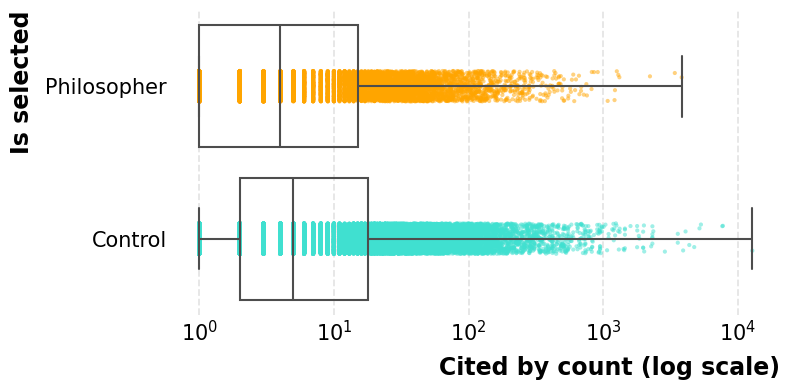

In [106]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# df is your original dataframe

# Copy and clean
df_plot = df_stacked.copy()

# Ensure cited_by_count is numeric and positive
df_plot["cited_by_count"] = pd.to_numeric(df_plot["cited_by_count"], errors="coerce")
df_plot = df_plot.dropna(subset=["cited_by_count"])
df_plot = df_plot[df_plot["cited_by_count"] > 0]

# Normalize is_selected into a clean categorical column
df_plot["is_selected_clean"] = df_plot["is_selected"].map(
    {
        True: "Philosopher",
        False: "Control",
        "True": "Philsopher",
        "False": "Control",
    }
)

# Drop any rows that did not map
df_plot = df_plot.dropna(subset=["is_selected_clean"])

# Compute and print group means and medians
group_stats = df_plot.groupby("is_selected_clean")["cited_by_count"].agg(["count", "mean", "median"])
print("Cited by counts per group:")
print(group_stats)

# Plot
plt.figure(figsize=(8, 4))

palette = {
    "Philosopher": "orange",
    "Control": "turquoise",
}

# Strip plot in the background to show the full distribution
sns.stripplot(
    data=df_plot,
    x="cited_by_count",
    y="is_selected_clean",
    hue="is_selected_clean",
    palette=palette,
    orient="h",
    dodge=False,
    alpha=0.5,
    size=3,
    zorder=1,
    legend=False,
)

# Boxplot on top
# - no outlier selection: whiskers span full range (0, 100)
# - no separate outlier markers: showfliers=False
# - no box fill: facecolor set to none
sns.boxplot(
    data=df_plot,
    x="cited_by_count",
    y="is_selected_clean",
    hue="is_selected_clean",
    palette=palette,
    orient="h",
    dodge=False,
    whis=(0, 100),
    showfliers=False,
    linewidth=1.5,
    boxprops={"facecolor": "none"},
    zorder=2,
    legend=False,
)

ax = plt.gca()
ax.set_xscale("log")
ax.set_xlabel("Cited by count (log scale)")
ax.set_ylabel("Is selected")

plt.tight_layout()
plt.show()

In [99]:
df_plot['selected_work_id'].value_counts()

selected_work_id
https://openalex.org/W2603669607    4
https://openalex.org/W2316151347    4
https://openalex.org/W2057000958    4
https://openalex.org/W1975199543    4
https://openalex.org/W2901878170    4
                                   ..
https://openalex.org/W2800285766    1
https://openalex.org/W772693246     1
https://openalex.org/W773348293     1
https://openalex.org/W776642077     1
https://openalex.org/W806175103     1
Name: count, Length: 20952, dtype: int64

In [97]:
df_plot

,Unnamed: 0,work_id,selected_work_id,scenario,year_diff,author_diff,journal_key,year,n_authors,referenced_works,n_references,cited_by_count,is_selected,is_selected_clean
493,493,https://openalex.org/W2466549537,https://openalex.org/W2466549537,NaN,NaN,NaN,1768-9260,1974,1,NaN,NaN,25,True,Philosopher
494,494,https://openalex.org/W2098367015,https://openalex.org/W2098367015,NaN,NaN,NaN,0002-9556,1965,2,NaN,NaN,13,True,Philosopher
495,495,https://openalex.org/W628693861,https://openalex.org/W628693861,NaN,NaN,NaN,0009-4978,2001,1,NaN,NaN,9,True,Philosopher
496,496,https://openalex.org/W1980818393,https://openalex.org/W1980818393,NaN,NaN,NaN,0539-0184,1983,1,NaN,NaN,8,True,Philosopher
497,497,https://openalex.org/W2057218894,https://openalex.org/W2057218894,NaN,NaN,NaN,0036-8075,1963,1,NaN,NaN,7,True,Philosopher
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107959,107959,https://openalex.org/W4254170707,https://openalex.org/W993389733,1.0,0.0,1.0,0016-2736,1964,3,[],0.0,3,False,Control
107968,107968,https://openalex.org/W2072654002,https://openalex.org/W99780763,1.0,1.0,0.0,0210-3702,1980,1,[],0.0,3,False,Control
107970,107970,https://openalex.org/W250919782,https://openalex.org/W999059237,2.0,2.0,0.0,0016-2736,1980,1,[],0.0,4,False,Control
107971,107971,https://openalex.org/W938665567,https://openalex.org/W999059237,1.0,1.0,0.0,0016-2736,1977,1,[],0.0,1,False,Control


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# --------------------------------------------
# 0) Start from your DataFrame
# --------------------------------------------
# Assumes you already have df_stacked in memory with the columns you listed:
# ['Unnamed: 0','work_id','selected_work_id','scenario','year_diff','author_diff',
#  'journal_key','year','n_authors','referenced_works','n_references',
#  'cited_by_count','is_selected','is_selected_clean']

df = df_stacked.copy()

# --------------------------------------------
# 1) Basic cleaning and filtering
# --------------------------------------------
# Keep rows that have a nonmissing group id, treatment label, and citation count
df = df.dropna(subset=['selected_work_id', 'is_selected_clean', 'cited_by_count'])

# Coerce cited_by_count to numeric, guard against bad parses and negatives
df['cited_by_count'] = pd.to_numeric(df['cited_by_count'], errors='coerce')
df = df.dropna(subset=['cited_by_count'])
df['cited_by_count'] = df['cited_by_count'].clip(lower=0)

# --------------------------------------------
# 2) Drop groups with fewer than 4 rows
# --------------------------------------------
group_sizes = df.groupby('selected_work_id')['selected_work_id'].transform('size')
df = df.loc[group_sizes >= 4].copy()

# If nothing remains, bail out early
if df.empty:
    raise ValueError("No groups have at least 4 rows after filtering. Check your data or the threshold.")

# --------------------------------------------
# 3) Build treatment indicator from is_selected_clean
#    1 for Philosopher, 0 for Control
# --------------------------------------------
df['is_selected_clean'] = df['is_selected_clean'].astype(str).str.strip()
df['philosopher'] = df['is_selected_clean'].str.lower().eq('philosopher').astype(int)

# --------------------------------------------
# 4) Construct outcome: log citations
# --------------------------------------------
df['log_cites'] = np.log1p(df['cited_by_count'])

# --------------------------------------------
# 5) For a within set effect with fixed effects, we need variation in treatment within each set.
#    Drop sets that are all treated or all control
# --------------------------------------------
has_variation = (
    df.groupby('selected_work_id')['philosopher']
      .transform('nunique')
)
df_fe = df.loc[has_variation > 1].copy()

if df_fe['selected_work_id'].nunique() == 0:
    raise ValueError("After filtering, no matched set has both Philosopher and Control. Cannot estimate a within-set effect.")

# Optional memory improvement
df_fe['selected_work_id'] = df_fe['selected_work_id'].astype('category')

# --------------------------------------------
# 6) Fixed effects OLS on log citations with cluster-robust SE by set
#    Model: log_cites ~ philosopher + C(selected_work_id)
# --------------------------------------------
fe_formula = 'log_cites ~ philosopher + C(selected_work_id)'
fe_model = smf.ols(fe_formula, data=df_fe)
fe_res = fe_model.fit(cov_type='cluster', cov_kwds={'groups': df_fe['selected_work_id']})

# Extract key effect and convert to multiplicative change on raw citations
beta = fe_res.params['philosopher']
beta_se = fe_res.bse['philosopher']
ci = fe_res.conf_int().loc['philosopher'].to_numpy()
rr = float(np.exp(beta))
rr_ci_low = float(np.exp(ci[0]))
rr_ci_high = float(np.exp(ci[1]))

n_obs = int(df_fe.shape[0])
n_sets = int(df_fe['selected_work_id'].nunique())
n_treated_sets = int(
    df_fe.groupby('selected_work_id')['philosopher'].max().sum()
)
n_control_sets = int(n_sets - n_treated_sets)

print("Fixed effects OLS with cluster SEs by selected_work_id")
print(f"Observations used: {n_obs}")
print(f"Matched sets used: {n_sets}  "
      f"(sets with any Philosopher: {n_treated_sets}, sets with only Control after filtering were dropped)")
print("")
print("Effect of Philosopher on log citations (within set):")
print(f"  Coef on philosopher: {beta:.4f}  SE: {beta_se:.4f}")
print(f"  95% CI for coef: [{ci[0]:.4f}, {ci[1]:.4f}]")
print("")
print("Interpretation on raw citations (multiplicative):")
print(f"  Rate ratio exp(beta): {rr:.3f}")
print(f"  95% CI for rate ratio: [{rr_ci_low:.3f}, {rr_ci_high:.3f}]")

# If you really want the full summary, it will print thousands of dummy coefficients.
# Uncomment the next line at your own risk.
# print(fe_res.summary())

# --------------------------------------------
# 7) Optional robustness: random intercept mixed model
#    Uses selected_work_id as a grouping variable for the intercept
#    Note: this is a different identifying assumption than fixed effects
# --------------------------------------------
RUN_MIXEDLM = False  # set to True if you want to fit it

if RUN_MIXEDLM:
    # Keep the same df_fe so we preserve groups with both treatment states
    # MixedLM will be faster if group ids are categorical
    df_fe['selected_work_id'] = df_fe['selected_work_id'].astype('category')
    mx_formula = 'log_cites ~ philosopher'
    mx_model = smf.mixedlm(mx_formula, data=df_fe, groups=df_fe['selected_work_id'])
    mx_res = mx_model.fit(method='lbfgs', reml=True)
    beta_mx = mx_res.params['philosopher']
    ci_mx = mx_res.conf_int().loc['philosopher'].to_numpy()
    rr_mx = float(np.exp(beta_mx))
    rr_mx_ci_low = float(np.exp(ci_mx[0]))
    rr_mx_ci_high = float(np.exp(ci_mx[1]))

    print("\nRandom intercept mixed model on log citations")
    print(f"  Coef on philosopher: {beta_mx:.4f}")
    print(f"  95% CI for coef: [{ci_mx[0]:.4f}, {ci_mx[1]:.4f}]")
    print(f"  Rate ratio exp(beta): {rr_mx:.3f}")
    print(f"  95% CI for rate ratio: [{rr_mx_ci_low:.3f}, {rr_mx_ci_high:.3f}]")

In [101]:
!pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 54.7 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]


In [103]:
df_plot['journal_key'].value_counts()

journal_key
0009-4978    835
1556-5068    665
2330-4014    415
0140-525X    389
0009-8388    343
            ... 
0004-9638      1
0895-0016      1
0152-0032      1
2083-5345      1
0023-5881      1
Name: count, Length: 7444, dtype: int64

In [19]:
import os, glob, sys, io, gzip, random, string, time, ast
from pathlib import Path
from typing import Tuple, Dict, List, Any
from concurrent.futures import ProcessPoolExecutor, as_completed
from collections.abc import Iterable as ABCIterable

import pandas as pd
from tqdm.auto import tqdm

# -------------- Configuration --------------
SNAPSHOT_ROOT = "openalex-snapshot_3_11_2025"
WORKS_GLOB = os.path.join(SNAPSHOT_ROOT, "data", "works", "updated_date=*","part_*.gz")

# You already have these in your notebook:
# PROJECT_DIR: path to your project root
# selected_works_df: DataFrame of focal works you want matches for

BASE_OUT        = os.path.join(PROJECT_DIR, "journal_year_author_matches_2")
OUT_DATA_DIR    = os.path.join(BASE_OUT, "works_matches_ndjson")   # full JSON lines
OUT_LINKS_DIR   = os.path.join(BASE_OUT, "match_links_tsv")        # link tables
OUT_FLAT_DIR    = os.path.join(BASE_OUT, "works_flat_parquet")     # fast to read

LOG_DIR         = os.path.join(BASE_OUT, "logs")
DONE_DIR        = os.path.join(BASE_OUT, "done_marks")  # resume support

for d in [BASE_OUT, OUT_DATA_DIR, OUT_LINKS_DIR, OUT_FLAT_DIR, LOG_DIR, DONE_DIR]:
    Path(d).mkdir(parents=True, exist_ok=True)

# Flush buffers after this many matched lines
BLOCK_SIZE_LINES = 10_000

COMPRESS_OUT     = False  # True -> write .ndjson.gz

_CPU_COUNT = os.cpu_count() or 1
N_WORKERS  = max(1, _CPU_COUNT - 4)  # use n_cores - 4

# Scenario radii: plus minus 1, 2, 3 years and authors
SCENARIO_LEVELS = (1, 2, 3)
MAX_YEAR_DIFF   = max(SCENARIO_LEVELS)
MAX_AUTH_DIFF   = max(SCENARIO_LEVELS)

# Flat parquet configuration for fast loading
WRITE_FLAT_PARQUET      = True
FLAT_PARQUET_CHUNK_ROWS = 50_000  # rows per parquet chunk file

# -------------- Optional faster JSON --------------
try:
    import orjson as _fastjson_backend
    def _loads(b: bytes) -> Any:
        return _fastjson_backend.loads(b)
    def _dumps(obj: Any) -> bytes:
        return _fastjson_backend.dumps(obj)
except Exception:
    import json as _fastjson_backend
    def _loads(b: bytes) -> Any:
        return _fastjson_backend.loads(b.decode("utf-8"))
    def _dumps(obj: Any) -> bytes:
        return _fastjson_backend.dumps(obj).encode("utf-8")

# -------------- Optional faster gzip reads --------------
try:
    from isal import igzip as igzip
    _use_igzip = True
except Exception:
    igzip = None
    _use_igzip = False

def _pick_reader():
    if _use_igzip:
        return igzip.open
    return gzip.open

# -------------- Generic missing value helper --------------
def _is_missing(v: Any) -> bool:
    """
    Treat None and scalar NaNs as missing.
    Treat sequences (lists, tuples, sets, arrays) as non missing.
    Strings are missing only if empty or whitespace.
    """
    if v is None:
        return True

    if isinstance(v, str):
        return not v.strip()

    if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
        # For lists or arrays we treat "exists at all" as non missing
        return False

    try:
        return bool(pd.isna(v))
    except Exception:
        return False

# -------------- Selected works index helpers --------------
def _norm_work_id(x: str) -> str:
    """Normalize work IDs to full OpenAlex URL without trailing slash."""
    x = str(x).strip()
    if not x:
        return ""
    if x.lower().startswith("http"):
        return x.rstrip("/")
    x = x.upper()
    if x.startswith("W"):
        return "https://openalex.org/" + x
    return x.rstrip("/")

def _count_authors_from_row(row: pd.Series) -> int:
    """
    Best effort author count from a row in selected_works_df.
    Handles lists, arrays and stringified lists.
    """
    for col in ("author_ids", "authors"):
        if col not in row.index:
            continue
        v = row[col]
        if _is_missing(v):
            continue

        # List-like (list, tuple, set, numpy array etc)
        if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
            try:
                return len(v)
            except TypeError:
                pass

        # String, possibly "['id1', 'id2']" or "name1, name2"
        if isinstance(v, str):
            s = v.strip()
            if not s:
                continue

            # Try to parse as Python literal list
            if s.startswith("[") and s.endswith("]"):
                try:
                    parsed = ast.literal_eval(s)
                    if isinstance(parsed, ABCIterable) and not isinstance(parsed, (str, bytes)):
                        try:
                            return len(parsed)
                        except TypeError:
                            pass
                except Exception:
                    pass
                # Fallback: comma count
                return s.count(",") + 1

            # Otherwise treat as comma separated
            return s.count(",") + 1

        # Unknown non missing object, assume at least one author
        return 1

    return 0

def _norm_journal_from_row(row: pd.Series) -> str:
    """
    Build the journal_key for selected_works_df:
      - prefer issn_l if present
      - else issn
      - if list-like, take first element
      - if semicolon string, take part before first semicolon
    """
    v = None

    if "issn_l" in row.index and not _is_missing(row["issn_l"]):
        v = row["issn_l"]
    elif "issn" in row.index and not _is_missing(row["issn"]):
        v = row["issn"]

    if v is None:
        return ""

    if isinstance(v, ABCIterable) and not isinstance(v, (str, bytes)):
        v = next(iter(v), "")
    v = str(v).strip()
    if not v:
        return ""

    return v.split(";")[0].strip()

def build_selected_index(df: pd.DataFrame):
    """
    Build:
      journal_index: dict[journal_key] -> list of (selected_work_id, year, n_authors)
      selected_id_list: list of normalized selected work IDs
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("selected_works_df must be a pandas DataFrame")

    journal_index: Dict[str, List[Tuple[str, int, int]]] = {}
    selected_ids_set = set()

    missing = {"id", "year"} - set(df.columns)
    if missing:
        raise ValueError(f"selected_works_df is missing required columns: {missing}")

    for _, row in df.iterrows():
        journal_key = _norm_journal_from_row(row)
        if not journal_key:
            continue

        year_val = row["year"]
        try:
            year_int = int(year_val)
        except Exception:
            continue

        n_auth = _count_authors_from_row(row)
        work_id = _norm_work_id(row["id"])
        if not work_id:
            continue

        journal_index.setdefault(journal_key, []).append((work_id, year_int, n_auth))
        selected_ids_set.add(work_id)

    return journal_index, list(selected_ids_set)

# -------------- Raw works helpers (from OpenAlex JSON) --------------
def _extract_journal_from_work(obj: dict) -> str:
    """
    Build journal_key from a raw work:
      - host_venue.issn_l if available
      - else host_venue.issn (first element)
      - if host_venue missing, fall back to primary_location.source in same way
      - semicolon separated strings are cut at the first semicolon
    """
    venue = obj.get("host_venue")
    if not isinstance(venue, dict) or not venue:
        primary = obj.get("primary_location") or {}
        if isinstance(primary, dict):
            source = primary.get("source")
            if isinstance(source, dict):
                venue = source
    if not isinstance(venue, dict):
        return ""
    issn_l = venue.get("issn_l")
    if issn_l:
        return str(issn_l).strip()
    issn = venue.get("issn")
    if isinstance(issn, ABCIterable) and not isinstance(issn, (str, bytes)):
        issn = next(iter(issn), "")
    if isinstance(issn, str) and issn.strip():
        return issn.split(";")[0].strip()
    return ""

def _extract_year_from_work(obj: dict):
    y = obj.get("publication_year") or obj.get("year")
    if isinstance(y, int):
        return y
    if isinstance(y, str) and y.isdigit():
        return int(y)
    pub_date = obj.get("publication_date") or obj.get("from_publication_date")
    if isinstance(pub_date, str) and len(pub_date) >= 4 and pub_date[:4].isdigit():
        return int(pub_date[:4])
    return None

def _count_authors_from_work(obj: dict) -> int:
    auths = obj.get("authorships")
    if isinstance(auths, list):
        return len(auths)
    return 0

def _extract_citations_from_work(obj: dict):
    """
    Extract outgoing citations and counts:
      - referenced_works: list of work IDs this work cites
      - n_references: length of that list
      - cited_by_count: integer count of incoming citations (OpenAlex field)
    """
    refs = obj.get("referenced_works") or []
    if not isinstance(refs, list):
        refs = []
    n_refs = len(refs)

    cit_count = obj.get("cited_by_count")
    if cit_count is None:
        cit_count = 0
    else:
        try:
            cit_count = int(cit_count)
        except Exception:
            cit_count = 0

    return refs, n_refs, cit_count

# -------------- Global lookup for workers --------------
_MATCH_JOURNAL_INDEX: Dict[str, List[Tuple[str, int, int]]] = {}
_MATCH_SELECTED_IDS: set = set()

def _init_worker(journal_index, selected_ids, max_year_diff, max_auth_diff):
    """
    Called once per worker process. Stores shared lookup structures as globals.
    """
    global _MATCH_JOURNAL_INDEX, _MATCH_SELECTED_IDS, MAX_YEAR_DIFF, MAX_AUTH_DIFF
    _MATCH_JOURNAL_INDEX = journal_index
    _MATCH_SELECTED_IDS = set(selected_ids)
    MAX_YEAR_DIFF = max_year_diff
    MAX_AUTH_DIFF = max_auth_diff

def _done_mark_for(path: str) -> str:
    p = Path(path)
    return os.path.join(DONE_DIR, f"{p.parent.name}__{p.name}.done")

def _open_out_stream(path: str, compress: bool):
    if compress:
        return gzip.open(path, "wb")
    return open(path, "wb")

def _find_matches_for_work(journal_key: str, year: int, n_auth: int) -> List[Tuple[str, int, int, int]]:
    """
    Return list of matches for a work given its journal_key, year and n_auth.

    Each element is (selected_work_id, scenario_level, year_diff, author_diff).
    Scenario levels are 1, 2, 3 based on plus minus year and authors.
    """
    if not _MATCH_JOURNAL_INDEX:
        return []

    candidates = _MATCH_JOURNAL_INDEX.get(journal_key)
    if not candidates:
        return []

    matches: List[Tuple[str, int, int, int]] = []
    for sel_id, sel_year, sel_auth in candidates:
        dy = abs(year - sel_year)
        if dy > MAX_YEAR_DIFF:
            continue
        da = abs(n_auth - sel_auth)
        if da > MAX_AUTH_DIFF:
            continue
        scenario = None
        for s in SCENARIO_LEVELS:
            if dy <= s and da <= s:
                scenario = s
                break
        if scenario is None:
            continue
        matches.append((sel_id, scenario, dy, da))
    return matches

# -------------- Worker function --------------
def _worker_process_file(fpath: str,
                         out_data_dir: str,
                         out_links_dir: str,
                         block_lines: int,
                         compress_out: bool) -> Tuple[int, int, int, int]:
    """
    Process one gzipped works part file.

    Returns (seen, kept, errors, link_rows_written).
    """
    seen = kept = errors = link_rows = 0

    if os.path.exists(_done_mark_for(fpath)):
        return 0, 0, 0, 0

    try:
        updated_date = Path(fpath).parent.name.split("=", 1)[-1]
        partstem = Path(fpath).stem
        pid = os.getpid()
        rnd = "".join(random.choice(string.hexdigits.lower()) for _ in range(6))
        reader_open = _pick_reader()

        # Output file names for this input part
        data_out_name = f"matches_{updated_date}_{partstem}_pid{pid}_{rnd}" + (".ndjson.gz" if compress_out else ".ndjson")
        links_out_name = f"matches_{updated_date}_{partstem}_pid{pid}_{rnd}.tsv"

        data_out_path = os.path.join(out_data_dir, data_out_name)
        links_out_path = os.path.join(out_links_dir, links_out_name)

        data_buf: List[bytes] = []
        links_buf: List[str] = []
        data_fp = None
        links_fp = None

        # For fast Parquet flat output
        flat_buf: List[dict] = []
        flat_chunk_idx = 0
        flat_enabled = WRITE_FLAT_PARQUET

        link_header = "matched_work_id\tselected_work_id\tscenario\tyear_diff\tauthor_diff\n"

        with reader_open(fpath, "rb") as gz:
            for raw_line in gz:
                if not raw_line or raw_line == b"\n":
                    continue
                seen += 1
                try:
                    obj = _loads(raw_line)
                except Exception:
                    errors += 1
                    continue

                work_id = obj.get("id")
                if not work_id:
                    continue
                norm_id = _norm_work_id(work_id)

                # Skip if this work itself is in the selected set
                if norm_id in _MATCH_SELECTED_IDS:
                    continue

                # Extract journal, year, n_auth once
                journal_key = _extract_journal_from_work(obj)
                if not journal_key:
                    continue
                year = _extract_year_from_work(obj)
                if year is None:
                    continue
                n_auth = _count_authors_from_work(obj)

                # Find matches for these attributes
                matches = _find_matches_for_work(journal_key, year, n_auth)
                if not matches:
                    continue

                kept += 1

                # Extract citation info
                referenced_works, n_references, cited_by_count = _extract_citations_from_work(obj)

                # Link records (TSV with labeled columns)
                for sel_id, scenario, dy, da in matches:
                    links_buf.append(f"{norm_id}\t{sel_id}\t{scenario}\t{dy}\t{da}\n")
                link_rows += len(matches)

                # Annotate object with match info and dump full JSON line
                obj["_matched_to"] = [
                    {
                        "selected_id": sel_id,
                        "scenario": scenario,
                        "year_diff": dy,
                        "author_diff": da,
                    }
                    for sel_id, scenario, dy, da in matches
                ]
                out_bytes = _dumps(obj)
                if not out_bytes.endswith(b"\n"):
                    out_bytes += b"\n"
                data_buf.append(out_bytes)

                # Flat record for fast Parquet loading (including citations)
                if flat_enabled:
                    flat_buf.append(
                        {
                            "work_id": norm_id,
                            "journal_key": journal_key,
                            "year": year,
                            "n_authors": n_auth,
                            "referenced_works": referenced_works,
                            "n_references": n_references,
                            "cited_by_count": cited_by_count,
                        }
                    )

                # Flush NDJSON buffer
                if len(data_buf) >= block_lines:
                    if data_fp is None:
                        data_fp = _open_out_stream(data_out_path, compress_out)
                    data_fp.writelines(data_buf)
                    data_buf.clear()

                # Flush link buffer
                if len(links_buf) >= block_lines:
                    if links_fp is None:
                        links_fp = open(links_out_path, "w", encoding="utf-8")
                        links_fp.write(link_header)
                    links_fp.writelines(links_buf)
                    links_buf.clear()

                # Flush flat Parquet buffer
                if flat_enabled and len(flat_buf) >= FLAT_PARQUET_CHUNK_ROWS:
                    try:
                        df_flat = pd.DataFrame(flat_buf)
                        flat_out_name = f"matches_flat_{updated_date}_{partstem}_pid{pid}_{rnd}_chunk{flat_chunk_idx:05d}.parquet"
                        flat_out_path = os.path.join(OUT_FLAT_DIR, flat_out_name)
                        df_flat.to_parquet(flat_out_path, index=False)
                        flat_chunk_idx += 1
                        flat_buf.clear()
                    except Exception as e:
                        flat_enabled = False
                        err_path = os.path.join(LOG_DIR, "parquet_errors.log")
                        with open(err_path, "a", encoding="utf-8") as lf:
                            lf.write(f"{fpath}\t{repr(e)}\n")

        # Final flush NDJSON
        if data_buf:
            if data_fp is None:
                data_fp = _open_out_stream(data_out_path, compress_out)
            data_fp.writelines(data_buf)

        # Final flush links
        if links_buf:
            if links_fp is None:
                links_fp = open(links_out_path, "w", encoding="utf-8")
                links_fp.write(link_header)
            links_fp.writelines(links_buf)

        # Final flush flat Parquet
        if flat_enabled and flat_buf:
            try:
                df_flat = pd.DataFrame(flat_buf)
                flat_out_name = f"matches_flat_{updated_date}_{partstem}_pid{pid}_{rnd}_chunk{flat_chunk_idx:05d}.parquet"
                flat_out_path = os.path.join(OUT_FLAT_DIR, flat_out_name)
                df_flat.to_parquet(flat_out_path, index=False)
            except Exception as e:
                err_path = os.path.join(LOG_DIR, "parquet_errors.log")
                with open(err_path, "a", encoding="utf-8") as lf:
                    lf.write(f"{fpath}\t{repr(e)}\n")

        if data_fp is not None:
            data_fp.close()
        if links_fp is not None:
            links_fp.close()

        Path(_done_mark_for(fpath)).touch()
        return seen, kept, errors, link_rows

    except Exception as e:
        err_path = os.path.join(LOG_DIR, "worker_errors.log")
        with open(err_path, "a", encoding="utf-8") as lf:
            lf.write(f"{fpath}\t{repr(e)}\n")
        return seen, kept, errors + 1, link_rows

# -------------- Driver --------------
def run_match_extraction(selected_works_df: pd.DataFrame):
    files = sorted(glob.glob(WORKS_GLOB))
    if not files:
        print("No input files found. Check SNAPSHOT_ROOT and WORKS_GLOB.")
        return

    print(f"Files to scan: {len(files)}")
    print(f"Workers: {N_WORKERS}  Buffer lines: {BLOCK_SIZE_LINES}  Compress out: {COMPRESS_OUT}")
    if _use_igzip:
        print("Using isal.igzip for input decompression")
    if _fastjson_backend.__name__ == "orjson":
        print("Using orjson for JSON parsing")

    # Build index of selected works
    print("Building lookup index from selected_works_df ...")
    journal_index, selected_ids = build_selected_index(selected_works_df)
    print(f"Indexed journals: {len(journal_index):,}  selected works: {len(selected_ids):,}")
    print("Matching key for publication (journal) is journal_key based on issn_l or issn as described in the code comments.")

    if not journal_index:
        print("No valid selected works with journal and year info. Nothing to do.")
        return

    # Filter out files already processed
    pending = [f for f in files if not os.path.exists(_done_mark_for(f))]
    skipped = len(files) - len(pending)
    if skipped:
        print(f"Skipping {skipped} files already marked done")

    total_seen = total_kept = total_errors = total_links = 0
    start = time.time()

    with ProcessPoolExecutor(
        max_workers=N_WORKERS,
        initializer=_init_worker,
        initargs=(journal_index, selected_ids, MAX_YEAR_DIFF, MAX_AUTH_DIFF),
    ) as ex:
        futs = {
            ex.submit(
                _worker_process_file,
                f,
                OUT_DATA_DIR,
                OUT_LINKS_DIR,
                BLOCK_SIZE_LINES,
                COMPRESS_OUT,
            ): f
            for f in pending
        }
        for fut in tqdm(as_completed(futs), total=len(futs), desc="Processing files"):
            seen, kept, errors, link_rows = fut.result()
            total_seen += seen
            total_kept += kept
            total_errors += errors
            total_links += link_rows

    elapsed = time.time() - start
    print("Done")
    print(f"Lines seen: {total_seen:,}  kept (works with any match): {total_kept:,}  parse or IO errors: {total_errors:,}")
    print(f"Match links written (rows): {total_links:,}")
    print(f"Elapsed: {elapsed:,.1f} s")
    print(f"Matched works NDJSON in: {OUT_DATA_DIR}")
    print(f"Match link tables (TSV, with header) in: {OUT_LINKS_DIR}")
    if WRITE_FLAT_PARQUET:
        print(f"Flat Parquet (fast to read, including referenced_works, n_references and cited_by_count) in: {OUT_FLAT_DIR}")

# Example call:
run_match_extraction(selected_works_df)

Files to scan: 1006
Workers: 11  Buffer lines: 10000  Compress out: False
Using isal.igzip for input decompression
Using orjson for JSON parsing
Building lookup index from selected_works_df ...
Indexed journals: 9,879  selected works: 36,853
Matching key for publication (journal) is journal_key based on issn_l or issn as described in the code comments.
Skipping 1006 files already marked done


Processing files: 0it [00:00, ?it/s]

Done
Lines seen: 0  kept (works with any match): 0  parse or IO errors: 0
Match links written (rows): 0
Elapsed: 0.0 s
Matched works NDJSON in: value_of_philosophy_datasets/journal_year_author_matches_2/works_matches_ndjson
Match link tables (TSV, with header) in: value_of_philosophy_datasets/journal_year_author_matches_2/match_links_tsv
Flat Parquet (fast to read, including referenced_works, n_references and cited_by_count) in: value_of_philosophy_datasets/journal_year_author_matches_2/works_flat_parquet


In [ ]:
import os, glob, gzip, random, json, hashlib
from pathlib import Path

import pandas as pd
from concurrent.futures import ProcessPoolExecutor, as_completed

# -------------------------------------------------
# Basic utilities and configuration
# -------------------------------------------------
CPU_COUNT = os.cpu_count() or 1
N_WORKERS_SECOND_STAGE = max(1, CPU_COUNT - 4)

def _norm_work_id(x) -> str:
    """Normalize work ids to full OpenAlex URL without trailing slash."""
    if pd.isna(x):
        return ""
    x = str(x).strip()
    if not x:
        return ""
    if x.lower().startswith("http"):
        return x.rstrip("/")
    x_up = x.upper()
    if x_up.startswith("W"):
        return "https://openalex.org/" + x_up
    return x.rstrip("/")

def _iter_match_link_files(match_links_dir: str):
    pattern = os.path.join(match_links_dir, "matches_*.tsv")
    return sorted(glob.glob(pattern))

def _iter_works_match_files(works_matches_dir: str):
    pattern = os.path.join(works_matches_dir, "matches_*.ndjson*")
    return sorted(glob.glob(pattern))

# -------------------------------------------------
# Helpers to extract metadata from OpenAlex work JSON
# -------------------------------------------------
def _extract_year_from_work(obj: dict):
    y = obj.get("publication_year") or obj.get("year")
    if isinstance(y, int):
        return y
    if isinstance(y, str) and y.isdigit():
        return int(y)
    pub_date = obj.get("publication_date") or obj.get("from_publication_date")
    if isinstance(pub_date, str) and len(pub_date) >= 4 and pub_date[:4].isdigit():
        return int(pub_date[:4])
    return None

def _extract_pub_date(obj: dict):
    return obj.get("publication_date") or obj.get("from_publication_date")

def _extract_doi_and_url(obj: dict):
    doi_val = obj.get("doi")
    if not isinstance(doi_val, str) or not doi_val.strip():
        return None, None
    s = doi_val.strip()
    if s.lower().startswith("http"):
        doi_url = s
        core = s.split("/")[-1]
        doi = core if core else None
    else:
        doi = s
        doi_url = "https://doi.org/" + s
    return doi, doi_url

def _extract_authors_lists(obj: dict):
    auths = obj.get("authorships")
    names = []
    ids = []
    if isinstance(auths, list):
        for a in auths:
            if not isinstance(a, dict):
                continue
            au = a.get("author")
            if not isinstance(au, dict):
                continue
            aid = au.get("id")
            name = au.get("display_name")
            if name:
                names.append(name)
            if aid:
                ids.append(aid)
    return names, ids

def _extract_journal_ids(obj: dict):
    venue = obj.get("host_venue")
    if not isinstance(venue, dict) or not venue:
        primary = obj.get("primary_location") or {}
        if isinstance(primary, dict):
            source = primary.get("source")
            if isinstance(source, dict):
                venue = source
    if not isinstance(venue, dict):
        return None, None
    issn_l = venue.get("issn_l")
    issn = venue.get("issn")
    if isinstance(issn, list):
        issn = issn[0] if issn else None
    return issn_l, issn

def _extract_biblio(obj: dict):
    biblio = obj.get("biblio") or {}
    if not isinstance(biblio, dict):
        biblio = {}
    volume = biblio.get("volume")
    issue = biblio.get("issue")
    first_page = biblio.get("first_page")
    last_page = biblio.get("last_page")
    return volume, issue, first_page, last_page

def _extract_topics(obj: dict):
    pt = obj.get("primary_topic")
    if not isinstance(pt, dict):
        topics = obj.get("topics")
        if isinstance(topics, list) and topics:
            first = topics[0]
            if isinstance(first, dict):
                pt = first
    if not isinstance(pt, dict):
        return None, None, None, None
    primary_topic = pt.get("display_name")
    field = None
    subfield = None
    domain = None
    fld = pt.get("field")
    if isinstance(fld, dict):
        field = fld.get("display_name")
    sf = pt.get("subfield")
    if isinstance(sf, dict):
        subfield = sf.get("display_name")
    dom = pt.get("domain")
    if isinstance(dom, dict):
        domain = dom.get("display_name")
    return primary_topic, field, subfield, domain

def _compute_cited_by_2yr(obj: dict):
    # Use counts_by_year if present
    cby = obj.get("counts_by_year")
    if not isinstance(cby, list) or not cby:
        val = obj.get("cited_by_count_2yr")
        return int(val) if isinstance(val, (int, float)) else None
    years = []
    for d in cby:
        if isinstance(d, dict):
            y = d.get("year")
            if isinstance(y, int):
                years.append(y)
    if not years:
        return None
    max_year = max(years)
    total = 0
    for d in cby:
        if not isinstance(d, dict):
            continue
        y = d.get("year")
        if not isinstance(y, int):
            continue
        if y >= max_year - 1:
            val = d.get("cited_by_count") or d.get("cited_by")
            if isinstance(val, (int, float)):
                total += int(val)
    return total

def extract_match_meta_record(obj: dict, target_cols) -> dict:
    """
    Build a dict for one matched work with keys chosen to match selected_works_df columns.
    Only fills keys that actually appear in target_cols.
    """
    rec = {}

    wid = _norm_work_id(obj.get("id", ""))
    if "id" in target_cols:
        rec["id"] = wid

    if "title" in target_cols:
        rec["title"] = obj.get("title") or obj.get("display_name")

    if "year" in target_cols:
        rec["year"] = _extract_year_from_work(obj)

    if "publication_date" in target_cols:
        rec["publication_date"] = _extract_pub_date(obj)

    if "doi" in target_cols or "doi_url" in target_cols:
        doi, doi_url = _extract_doi_and_url(obj)
        if "doi" in target_cols:
            rec["doi"] = doi
        if "doi_url" in target_cols:
            rec["doi_url"] = doi_url

    if "type" in target_cols:
        rec["type"] = obj.get("type")

    if "type_crossref" in target_cols:
        rec["type_crossref"] = obj.get("type_crossref")

    if "authors" in target_cols or "author_ids" in target_cols:
        names, ids = _extract_authors_lists(obj)
        if "authors" in target_cols:
            rec["authors"] = names
        if "author_ids" in target_cols:
            rec["author_ids"] = ids

    if "issn_l" in target_cols or "issn" in target_cols:
        issn_l, issn = _extract_journal_ids(obj)
        if "issn_l" in target_cols:
            rec["issn_l"] = issn_l
        if "issn" in target_cols:
            rec["issn"] = issn

    if any(c in target_cols for c in ("volume", "issue", "first_page", "last_page")):
        volume, issue, fp, lp = _extract_biblio(obj)
        if "volume" in target_cols:
            rec["volume"] = volume
        if "issue" in target_cols:
            rec["issue"] = issue
        if "first_page" in target_cols:
            rec["first_page"] = fp
        if "last_page" in target_cols:
            rec["last_page"] = lp

    if any(c in target_cols for c in ("primary_topic", "field", "subfield", "domain")):
        pt, fld, sfd, dom = _extract_topics(obj)
        if "primary_topic" in target_cols:
            rec["primary_topic"] = pt
        if "field" in target_cols:
            rec["field"] = fld
        if "subfield" in target_cols:
            rec["subfield"] = sfd
        if "domain" in target_cols:
            rec["domain"] = dom

    if "counts_by_year" in target_cols:
        rec["counts_by_year"] = obj.get("counts_by_year")

    if "cited_by_count_2yr" in target_cols:
        rec["cited_by_count_2yr"] = _compute_cited_by_2yr(obj)

    return rec

# -------------------------------------------------
# Parallel sampling of links
# -------------------------------------------------
_SAMPLE_SELECTED_IDS = set()
_SAMPLE_ALLOWED_SCENARIOS = set()
_SAMPLE_K = 0
_SAMPLE_SEED = 0

def _init_sample_worker(selected_ids, allowed_scenarios, k, seed):
    global _SAMPLE_SELECTED_IDS, _SAMPLE_ALLOWED_SCENARIOS, _SAMPLE_K, _SAMPLE_SEED
    _SAMPLE_SELECTED_IDS = set(selected_ids)
    _SAMPLE_ALLOWED_SCENARIOS = set(allowed_scenarios)
    _SAMPLE_K = int(k)
    _SAMPLE_SEED = int(seed)

def _row_score(selected_id, matched_id, scenario, dy, da):
    s = f"{_SAMPLE_SEED}|{selected_id}|{matched_id}|{scenario}|{dy}|{da}"
    h = hashlib.blake2b(s.encode("utf-8"), digest_size=8)
    return int.from_bytes(h.digest(), "big")

def _worker_sample_links_chunk(file_paths):
    """
    Process a list of match_links tsv files and return a dict:
      selected_id -> list of tuples (score, matched_id, scenario, year_diff, author_diff)
    """
    best = {}  # selected_id -> list of tuples

    for path in tqdm(file_paths):
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.rstrip("\n")
                if not line:
                    continue
                parts = line.split("\t")
                if len(parts) != 5:
                    continue
                matched_id_raw, selected_id_raw, scen_str, dy_str, da_str = parts
                selected_id = _norm_work_id(selected_id_raw)
                if selected_id not in _SAMPLE_SELECTED_IDS:
                    continue
                try:
                    scenario = int(scen_str)
                except Exception:
                    continue
                if scenario not in _SAMPLE_ALLOWED_SCENARIOS:
                    continue
                try:
                    year_diff = int(dy_str)
                    author_diff = int(da_str)
                except Exception:
                    continue
                matched_id = _norm_work_id(matched_id_raw)
                if not matched_id:
                    continue
                score = _row_score(selected_id, matched_id, scenario, year_diff, author_diff)
                lst = best.get(selected_id)
                if lst is None:
                    lst = []
                    best[selected_id] = lst
                if len(lst) < _SAMPLE_K:
                    lst.append((score, matched_id, scenario, year_diff, author_diff))
                else:
                    # find worst
                    worst_idx = max(range(len(lst)), key=lambda i: lst[i][0])
                    if score < lst[worst_idx][0]:
                        lst[worst_idx] = (score, matched_id, scenario, year_diff, author_diff)
    return best

def sample_links_for_selected_parallel(
    match_links_dir: str,
    selected_df: pd.DataFrame,
    samples_per_selected: int = 4,
    allowed_scenarios=(1, 2, 3),
    seed: int = 123,
    n_workers: int = None,
) -> pd.DataFrame:
    """
    Parallel version of sampling links.

    Returns DataFrame with columns:
      matched_id, selected_id, scenario, year_diff, author_diff
    """
    if n_workers is None:
        n_workers = N_WORKERS_SECOND_STAGE

    if "id" not in selected_df.columns:
        raise ValueError("selected_works_df must have an 'id' column")

    selected_ids_norm = selected_df["id"].map(_norm_work_id)
    selected_ids_norm = selected_ids_norm[selected_ids_norm != ""]
    selected_ids_set = set(selected_ids_norm)

    files = _iter_match_link_files(match_links_dir)
    if not files:
        raise FileNotFoundError(f"No match_links files found in {match_links_dir}")

    print(f"Sampling links from {len(files)} match_links files using {n_workers} workers...")

    # Split files into chunks
    n_workers_eff = min(n_workers, len(files))
    chunk_size = (len(files) + n_workers_eff - 1) // n_workers_eff
    chunks = [files[i:i + chunk_size] for i in range(0, len(files), chunk_size)]

    global_best = {}  # selected_id -> list of tuples (score, matched_id, scenario, year_diff, author_diff)

    with ProcessPoolExecutor(
        max_workers=n_workers_eff,
        initializer=_init_sample_worker,
        initargs=(list(selected_ids_set), list(allowed_scenarios), samples_per_selected, seed),
    ) as ex:
        futs = {ex.submit(_worker_sample_links_chunk, ch): ch for ch in chunks}
        for fut in tqdm(as_completed(futs)):
            part_best = fut.result()
            # merge into global_best
            for sid, lst in part_best.items():
                existing = global_best.get(sid, [])
                combined = existing + lst
                if len(combined) > samples_per_selected:
                    combined.sort(key=lambda t: t[0])
                    combined = combined[:samples_per_selected]
                global_best[sid] = combined

    # Flatten into records
    records = []
    for sel_id, lst in global_best.items():
        for score, matched_id, scenario, year_diff, author_diff in lst:
            records.append(
                {
                    "matched_id": matched_id,
                    "selected_id": sel_id,
                    "scenario": scenario,
                    "year_diff": year_diff,
                    "author_diff": author_diff,
                }
            )

    links_sample_df = pd.DataFrame.from_records(records)
    if not links_sample_df.empty:
        print(f"Sampled {len(links_sample_df):,} match rows for {links_sample_df['selected_id'].nunique():,} selected works.")
    else:
        print("No matches sampled.")
    return links_sample_df

# -------------------------------------------------
# Parallel load of matched metadata
# -------------------------------------------------
_META_TARGET_IDS = set()
_META_TARGET_COLS = []

def _init_meta_worker(target_ids, target_cols):
    global _META_TARGET_IDS, _META_TARGET_COLS
    _META_TARGET_IDS = set(target_ids)
    _META_TARGET_COLS = list(target_cols)

def _worker_read_meta_chunk(file_paths):
    local_records = []
    for path in tqdm(file_paths):
        if path.endswith(".gz"):
            opener = gzip.open
            mode = "rb"
        else:
            opener = open
            mode = "rb"
        with opener(path, mode) as f:
            for raw in f:
                if not raw:
                    continue
                if isinstance(raw, bytes):
                    try:
                        obj = json.loads(raw.decode("utf-8"))
                    except Exception:
                        continue
                else:
                    try:
                        obj = json.loads(raw)
                    except Exception:
                        continue
                wid = _norm_work_id(obj.get("id", ""))
                if not wid or wid not in _META_TARGET_IDS:
                    continue
                rec = extract_match_meta_record(obj, _META_TARGET_COLS)
                local_records.append(rec)
    return local_records

def load_sampled_matched_meta_parallel(
    works_matches_dir: str,
    links_sample_df: pd.DataFrame,
    target_cols,
    n_workers: int = None,
) -> pd.DataFrame:
    """
    Parallel version of loading metadata for sampled matched works.
    """
    if n_workers is None:
        n_workers = N_WORKERS_SECOND_STAGE

    if links_sample_df.empty:
        raise ValueError("links_sample_df is empty, nothing to load.")

    target_ids = set(links_sample_df["matched_id"].map(_norm_work_id))
    target_ids.discard("")
    if not target_ids:
        raise ValueError("No valid matched ids to load.")

    files = _iter_works_match_files(works_matches_dir)
    if not files:
        raise FileNotFoundError(f"No works_matches files found in {works_matches_dir}")

    print(f"Need metadata for {len(target_ids):,} matched works.")
    print(f"Scanning {len(files)} works_matches files using {n_workers} workers...")

    n_workers_eff = min(n_workers, len(files))
    chunk_size = (len(files) + n_workers_eff - 1) // n_workers_eff
    chunks = [files[i:i + chunk_size] for i in range(0, len(files), chunk_size)]

    all_records = []

    with ProcessPoolExecutor(
        max_workers=n_workers_eff,
        initializer=_init_meta_worker,
        initargs=(list(target_ids), list(target_cols)),
    ) as ex:
        futs = {ex.submit(_worker_read_meta_chunk, ch): ch for ch in chunks}
        for fut in tqdm(as_completed(futs)):
            part_records = fut.result()
            all_records.extend(part_records)

    if not all_records:
        raise ValueError("Did not find any matched works in works_matches files for the sampled links.")

    matched_meta_df = pd.DataFrame.from_records(all_records)
    # Drop duplicates just in case
    if "id" in matched_meta_df.columns:
        matched_meta_df = matched_meta_df.drop_duplicates(subset="id")
    # Ensure all target columns exist
    matched_meta_df = matched_meta_df.reindex(columns=target_cols)
    print(f"Loaded metadata for {len(matched_meta_df):,} matched works.")
    return matched_meta_df

# -------------------------------------------------
# Build the long dataset (focal + matches) using the parallel helpers
# -------------------------------------------------
def build_long_matched_dataset_fast(
    selected_works_df: pd.DataFrame,
    match_links_dir: str,
    works_matches_dir: str,
    samples_per_selected: int = 4,
    allowed_scenarios=(1, 2, 3),
    seed: int = 123,
    n_workers: int = None,
):
    """
    Parallel version of the long dataset builder.

    Returns:
      combined_long_df, links_sample_df, matched_meta_df
    """
    if n_workers is None:
        n_workers = N_WORKERS_SECOND_STAGE

    target_cols = list(selected_works_df.columns)

    # 1) Parallel sample of match links
    links_sample_df = sample_links_for_selected_parallel(
        match_links_dir=match_links_dir,
        selected_df=selected_works_df,
        samples_per_selected=samples_per_selected,
        allowed_scenarios=allowed_scenarios,
        seed=seed,
        n_workers=n_workers,
    )

    if links_sample_df.empty:
        raise ValueError("No sampled matches found under the given scenario constraints.")

    # 2) Parallel load of matched metadata
    matched_meta_df = load_sampled_matched_meta_parallel(
        works_matches_dir=works_matches_dir,
        links_sample_df=links_sample_df,
        target_cols=target_cols,
        n_workers=n_workers,
    )

    # 3) Build long focal and match frames
    focal_df = selected_works_df.copy()
    focal_df["id"] = focal_df["id"].map(_norm_work_id)
    focal_df["role"] = "focal"
    focal_df["match_group_id"] = focal_df["id"]
    focal_df["scenario"] = pd.NA
    focal_df["year_diff"] = pd.NA
    focal_df["author_diff"] = pd.NA
    focal_df["matched_to_id"] = pd.NA

    match_df = links_sample_df.merge(
        matched_meta_df,
        left_on="matched_id",
        right_on="id",
        how="left",
        suffixes=("", "_meta"),
    )

    match_df["role"] = "match"
    match_df["match_group_id"] = match_df["selected_id"]
    match_df["matched_to_id"] = match_df["selected_id"]

    meta_cols = target_cols
    extra_cols = [
        "role",
        "match_group_id",
        "scenario",
        "year_diff",
        "author_diff",
        "matched_to_id",
        "matched_id",
        "selected_id",
    ]

    focal_long = focal_df.reindex(columns=meta_cols + extra_cols)
    match_long = match_df.reindex(columns=meta_cols + extra_cols)

    combined_long_df = pd.concat([focal_long, match_long], ignore_index=True)

    print(f"Combined long dataset has {len(combined_long_df):,} rows.")
    print(f"  focal rows: {len(focal_long):,}")
    print(f"  match rows: {len(match_long):,}")

    return combined_long_df, links_sample_df, matched_meta_df

# -------------------------------------------------
# Example usage
# -------------------------------------------------
MATCH_BASE_DIR = os.path.join(PROJECT_DIR, "journal_year_author_matches")
MATCH_LINKS_DIR = os.path.join(MATCH_BASE_DIR, "match_links")
WORKS_MATCHES_DIR = os.path.join(MATCH_BASE_DIR, "works_matches")
#
long_df, links_sample_df, matched_meta_df = build_long_matched_dataset_fast(
     selected_works_df=selected_works_df,
     match_links_dir=MATCH_LINKS_DIR,
     works_matches_dir=WORKS_MATCHES_DIR,
     samples_per_selected=4,
     allowed_scenarios=(1,),  # or (1,) or (1,2,3)
     seed=42,
     n_workers=None,            # or set explicitly
 )

Sampling links from 746 match_links files using 11 workers...


0it [00:00, ?it/s]

Sampled 106,471 match rows for 26,904 selected works.
Need metadata for 103,045 matched works.
Scanning 746 works_matches files using 11 workers...


0it [00:00, ?it/s]